Giảng viên hướng dẫn: Cô Vũ Thị Hạnh

Nhóm 6:
- Lê Trí Thiện
- Đặng Anh Tường
- Nguyễn Tuấn Minh

Dữ liệu:
- Ảnh thanh long: nhóm em tự quay video ở vườn rồi cắt khung hình ra làm ảnh, chia 6 lớp là khỏe mạnh (Dragon fruit healthy), nấm đỏ (red fungus), đốm vàng (yellow spot), nấm đồng tiền (coin spot), đốm dây (streak spot) và thối cành (stem rot). Tên bệnh nhóm em gọi theo cách người trồng ở địa phương hay gọi. Đây là phần chính của bài
  - 2000 ảnh quay ban ngày,
  - 640 ảnh quay lúc trời tối
- 2555 ảnh lá của 13 loại cây khác lấy từ bộ PlantDoc (Singh và cộng sự, 2020). Nhóm em đã lọc ảnh trùng và ảnh bị gắn 2 nhãn





In [ ]:
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
import os, re, time, random, shutil, copy, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [ ]:
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

THU_MUC = '/content/drive/MyDrive/KhaiPhaDuLieu/Nhom6_PlantDoc'
DATA = '/content/data'                     # ban sao tren may Colab
NGUON = os.path.join(THU_MUC, 'data')      # thu muc data tren Drive (anh sang va anh toi nam chung tung lop)

# doc thang thu muc data tren Drive, chep tung anh ve may Colab
# chep 32 file cung luc vi doc lan luot tung file tren Drive rat cham
from concurrent.futures import ThreadPoolExecutor
t = time.time()
ds_file = [(split, lop, f) for split in ['train', 'test']
           for lop in sorted(os.listdir(os.path.join(NGUON, split)))
           for f in os.listdir(os.path.join(NGUON, split, lop))]
for split, lop in set((a, b) for a, b, _ in ds_file):
    os.makedirs(os.path.join(DATA, split, lop), exist_ok=True)

def chep(x):
    dst = os.path.join(DATA, *x)
    if not os.path.exists(dst):
        shutil.copyfile(os.path.join(NGUON, *x), dst)
with ThreadPoolExecutor(32) as ex:
    list(ex.map(chep, ds_file))

# xoa anh tren may ma tren Drive khong con (vd lan truoc chay voi du lieu cu)
co_tren_drive = set(ds_file)
lop_tren_drive = set((a, b) for a, b, _ in ds_file)
for split in os.listdir(DATA):
    if split not in ['train', 'test']:
        shutil.rmtree(os.path.join(DATA, split))
        continue
    for lop in os.listdir(os.path.join(DATA, split)):
        if (split, lop) not in lop_tren_drive:
            shutil.rmtree(os.path.join(DATA, split, lop))
            continue
        for f in os.listdir(os.path.join(DATA, split, lop)):
            if (split, lop, f) not in co_tren_drive:
                os.remove(os.path.join(DATA, split, lop, f))
                p256 = os.path.join('/content/data256', split, lop, f)
                if os.path.exists(p256):
                    os.remove(p256)
print(f'Chep {len(ds_file)} anh tu Drive ve may xong sau {time.time() - t:.0f}s')
print('Anh toi:', sum(f.startswith('toi_') for _, _, f in ds_file))

# phong truong hop thu muc tren Drive chua doi ten lop
DOI_TEN = {
    'Dragon fruit black lesion': 'Dragon fruit red fungus',
    'Dragon fruit brown spot': 'Dragon fruit yellow spot',
    'Dragon fruit ring spot': 'Dragon fruit coin spot',
    'Dragon fruit brown spot early': 'Dragon fruit streak spot',
}
for split in ['train', 'test']:
    for cu, moi in DOI_TEN.items():
        if os.path.exists(os.path.join(DATA, split, cu)):
            os.rename(os.path.join(DATA, split, cu), os.path.join(DATA, split, moi))
print(os.listdir(DATA))

Mounted at /content/drive
Chep 5195 anh tu Drive ve may xong sau 94s
Anh toi: 640
['test', 'train']


## 1. Khám phá dữ liệu

### 1.1 Ảnh thanh long

Mỗi giây video nhóm em lấy tối đa 6 khung hình và bỏ những khung bị mờ. Train/test của từng lớp được chia như sau:
- Lớp khỏe mạnh và đốm vàng có từ 2 video sáng trở lên nên nhóm em để riêng 1 video làm test (thanhlong9 và thanhlong10). Mô hình chưa thấy cảnh trong 2 video này lần nào
- 4 lớp còn lại chỉ có 1 video sáng, nhóm em lấy 85% đầu video để train, phần cuối để test

Ảnh tối (tên file bắt đầu bằng `toi_`) cũng chia y như vậy. Khỏe mạnh và đốm dây có 2 video tối nên thanhlong13 và thanhlong18 được để riêng làm test. 4 lớp kia mỗi lớp chỉ có 1 video tối thì cắt 85% đầu làm train

In [ ]:
LOP_TL = ['Dragon fruit healthy', 'Dragon fruit red fungus', 'Dragon fruit yellow spot',
          'Dragon fruit coin spot', 'Dragon fruit streak spot', 'Dragon fruit stem rot']
LOP_PD = sorted(l for l in os.listdir(os.path.join(DATA, 'train')) if not l.startswith('Dragon fruit'))
print('So lop thanh long:', len(LOP_TL), '| so lop PlantDoc:', len(LOP_PD))

def doc_anh_tl(split):
    rows = []
    for lop in LOP_TL:
        p = os.path.join(DATA, split, lop)
        for f in sorted(os.listdir(p)):
            m = re.search(r'(thanhlong\d+)_f(\d+)\.jpg$', f)
            rows.append([split, lop, f, os.path.join(p, f), m.group(1) if m else '', int(m.group(2)) if m else -1, f.startswith('toi_')])
    return rows

tl = pd.DataFrame(doc_anh_tl('train') + doc_anh_tl('test'), columns=['split', 'lop', 'file', 'path', 'video', 'khung', 'toi'])
tl['loai'] = np.where(tl['toi'], 'toi', 'sang')
bang = tl.pivot_table(index='lop', columns=['split', 'loai'], values='file', aggfunc='count', fill_value=0).loc[LOP_TL]
bang.columns = [f'{a}_{b}' for a, b in bang.columns]
bang = bang[['train_sang', 'train_toi', 'test_sang', 'test_toi']]
bang['tong'] = bang.sum(axis=1)
bang['video_test'] = [', '.join(sorted(tl[(tl.lop == l) & (tl.split == 'test')].video.unique(), key=lambda v: int(v[9:]))) for l in bang.index]
print(bang.to_string())
print('\nTong anh thanh long:', len(tl), '| sang:', (~tl.toi).sum(), '| toi:', tl.toi.sum(),
      '| train:', (tl.split == 'train').sum(), '| test:', (tl.split == 'test').sum())

So lop thanh long: 6 | so lop PlantDoc: 27
                          train_sang  train_toi  test_sang  test_toi  tong                video_test
lop                                                                                                 
Dragon fruit healthy             419         80         74        80   653   thanhlong9, thanhlong13
Dragon fruit red fungus           55         68         10        12   145   thanhlong2, thanhlong17
Dragon fruit yellow spot         419         68         74        12   573  thanhlong10, thanhlong15
Dragon fruit coin spot           346         68         61        12   487   thanhlong8, thanhlong19
Dragon fruit streak spot         355         80         63        80   578   thanhlong5, thanhlong18
Dragon fruit stem rot            105         68         19        12   204   thanhlong3, thanhlong16

Tong anh thanh long: 2640 | sang: 2000 | toi: 640 | train: 2131 | test: 509


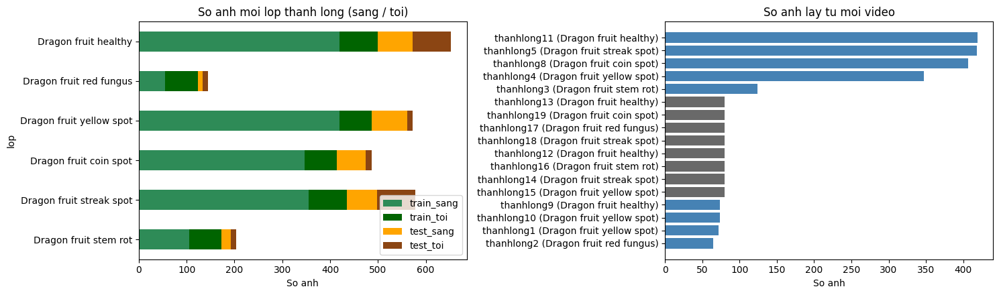

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
b = bang[['train_sang', 'train_toi', 'test_sang', 'test_toi']].copy()
b.plot(kind='barh', stacked=True, ax=ax[0], color=['seagreen', 'darkgreen', 'orange', 'saddlebrown'])
ax[0].set_title('So anh moi lop thanh long (sang / toi)')
ax[0].set_xlabel('So anh')
ax[0].invert_yaxis()

v = tl.groupby(['video', 'lop', 'toi']).size().reset_index(name='so_anh').sort_values('so_anh')
ax[1].barh(v['video'] + ' (' + v['lop'] + ')', v['so_anh'], color=np.where(v['toi'], 'dimgray', 'steelblue'))
ax[1].set_title('So anh lay tu moi video')
ax[1].set_xlabel('So anh')
plt.tight_layout()
plt.show()

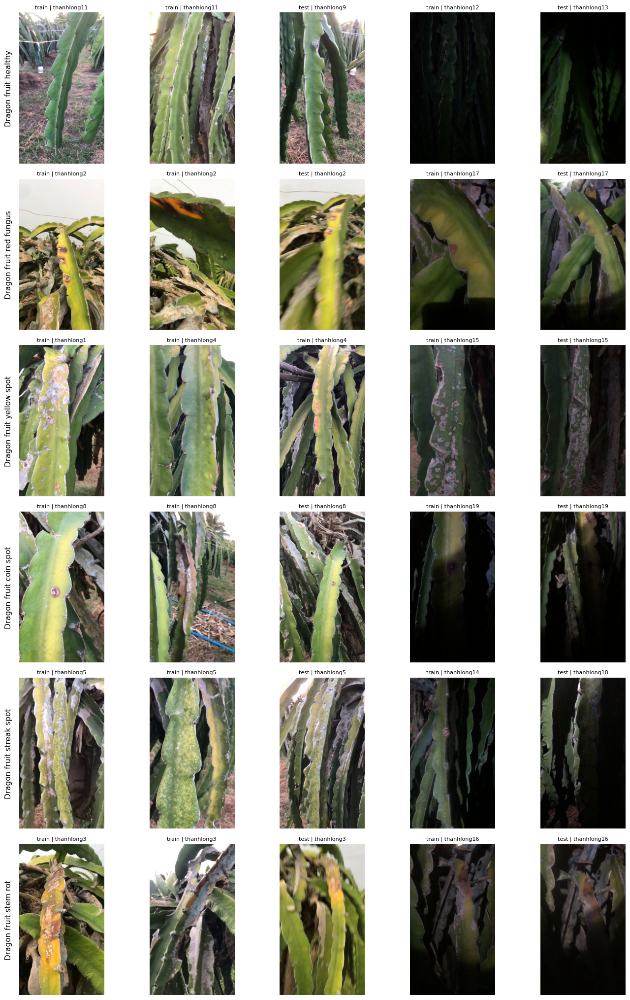

In [ ]:
# moi lop 3 anh sang, 2 anh toi
fig, ax = plt.subplots(len(LOP_TL), 5, figsize=(14, 3.4 * len(LOP_TL)))
for r, lop in enumerate(LOP_TL):
    ds_ = tl[(tl.lop == lop) & ~tl.toi].sort_values(['video', 'khung'])
    dt_ = tl[(tl.lop == lop) & tl.toi].sort_values(['video', 'khung'])
    chon = [ds_.iloc[k] for k in np.linspace(0, len(ds_) - 1, 3).astype(int)]
    chon += [dt_.iloc[k] for k in np.linspace(0, len(dt_) - 1, 2).astype(int)] if len(dt_) else []
    for c, row in enumerate(chon):
        ax[r, c].imshow(Image.open(row['path']))
        ax[r, c].set_title(f"{row['split']} | {row['video']}", fontsize=8)
        ax[r, c].axis('off')
    ax[r, 0].text(-0.08, 0.5, lop, transform=ax[r, 0].transAxes, rotation=90,
                  va='center', ha='right', fontsize=11)
plt.tight_layout()
plt.show()

### 1.2 Độ sáng của ảnh và ảnh PlantDoc

Do sang trung binh (0-255): anh sang 116.5 (300 anh mau), anh toi 31.5 (640 anh)
Anh toi sang nhat: 80.9 | anh sang toi nhat: 34.7


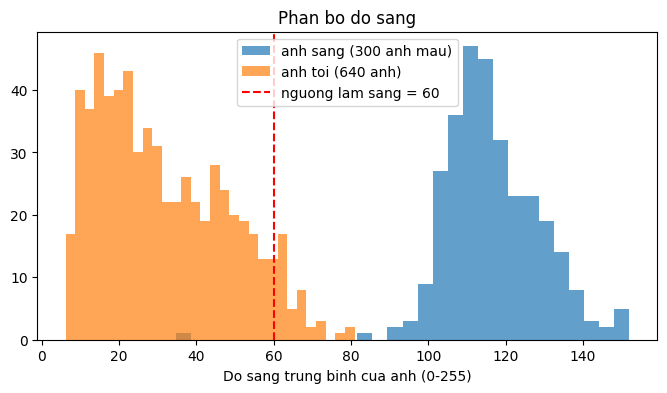

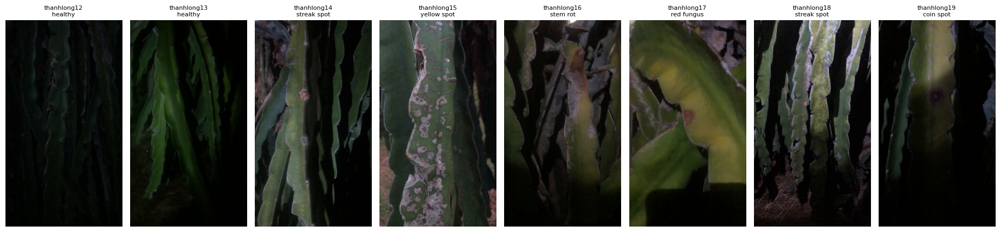

In [ ]:
def do_sang(path):
    with Image.open(path) as im:
        return np.asarray(im.convert('L').resize((128, 128))).mean()

mau_sang = tl[~tl.toi].sample(300, random_state=SEED)
sang_ngay = np.array([do_sang(p) for p in mau_sang['path']])
sang_toi = np.array([do_sang(p) for p in tl.loc[tl.toi, 'path']])
print(f'Do sang trung binh (0-255): anh sang {sang_ngay.mean():.1f} (300 anh mau), anh toi {sang_toi.mean():.1f} ({len(sang_toi)} anh)')
print(f'Anh toi sang nhat: {sang_toi.max():.1f} | anh sang toi nhat: {sang_ngay.min():.1f}')

plt.figure(figsize=(8, 4))
plt.hist(sang_ngay, bins=30, alpha=0.7, label='anh sang (300 anh mau)')
plt.hist(sang_toi, bins=30, alpha=0.7, label=f'anh toi ({len(sang_toi)} anh)')
plt.axvline(60, color='red', linestyle='--', label='nguong lam sang = 60')
plt.xlabel('Do sang trung binh cua anh (0-255)')
plt.title('Phan bo do sang')
plt.legend()
plt.show()

mau = tl[tl.toi].groupby('video').head(1)
mau = mau.iloc[mau['video'].str[9:].astype(int).argsort()]
fig, ax = plt.subplots(1, len(mau), figsize=(2.3 * len(mau), 4.5))
for a, (_, row) in zip(np.atleast_1d(ax), mau.iterrows()):
    a.imshow(Image.open(row['path']))
    a.set_title(f"{row['video']}\n{row['lop'].replace('Dragon fruit ', '')}", fontsize=8)
    a.axis('off')
plt.tight_layout()
plt.show()

Anh PlantDoc: 2555 | train: 2330 | test: 225


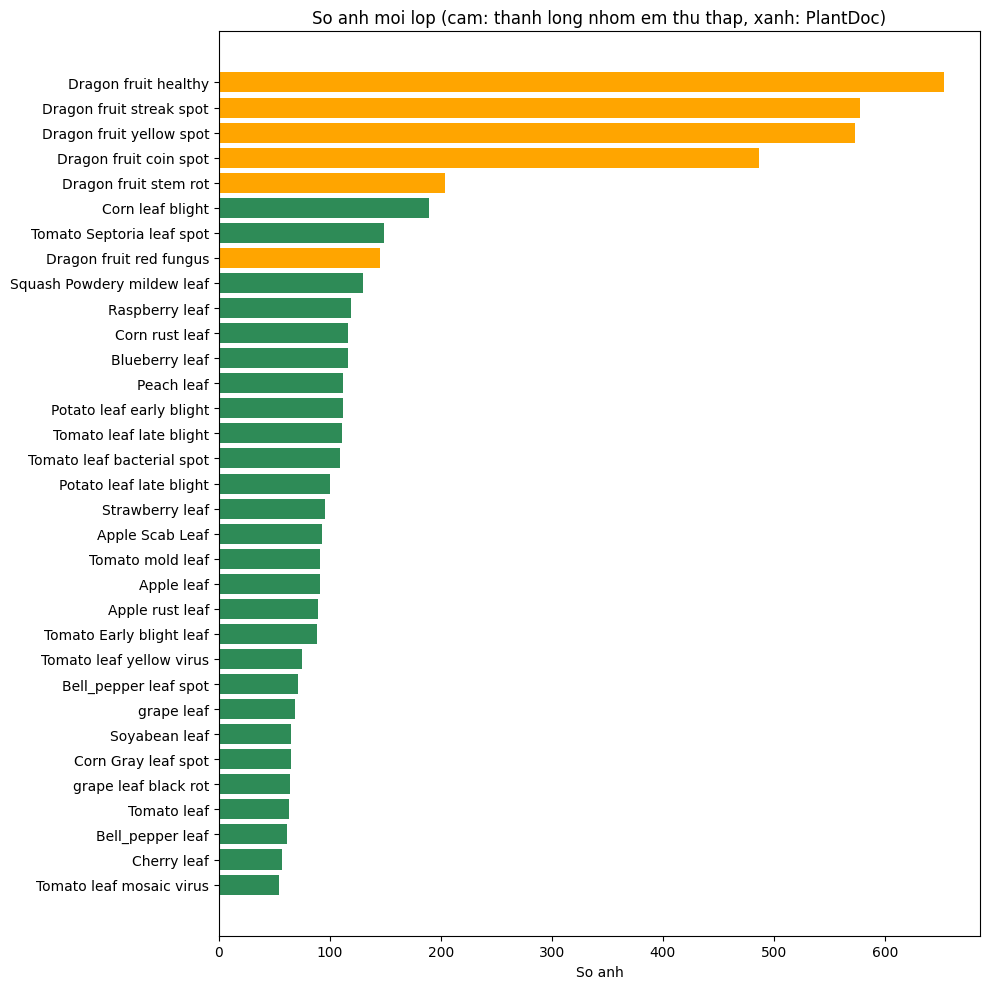

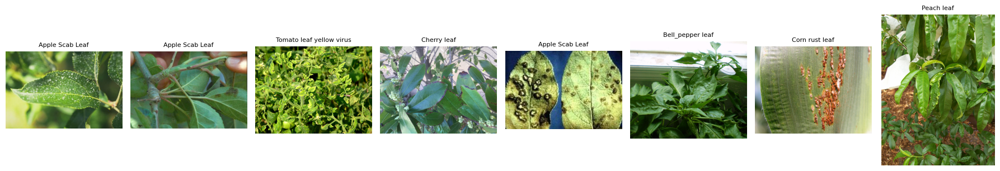

In [ ]:
# anh PlantDoc: giu nguyen 27 lop, dung toan bo anh train va test cua tac gia
pdoc = []
for split in ['train', 'test']:
    for lop in LOP_PD:
        for f in sorted(os.listdir(os.path.join(DATA, split, lop))):
            pdoc.append([split, lop, f, os.path.join(DATA, split, lop, f), '', -1, False, 'sang'])
pdoc = pd.DataFrame(pdoc, columns=tl.columns)
print('Anh PlantDoc:', len(pdoc), '| train:', (pdoc.split == 'train').sum(), '| test:', (pdoc.split == 'test').sum())

tat_ca = pd.concat([tl, pdoc])
dem_lop = tat_ca.groupby('lop').size().sort_values()
plt.figure(figsize=(10, 10))
plt.barh(list(dem_lop.index), dem_lop.values,
         color=['orange' if l in LOP_TL else 'seagreen' for l in dem_lop.index])
plt.title('So anh moi lop (cam: thanh long nhom em thu thap, xanh: PlantDoc)')
plt.xlabel('So anh')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 8, figsize=(18, 3))
for a, (_, row) in zip(ax, pdoc[pdoc.split == 'train'].sample(8, random_state=1).iterrows()):
    a.imshow(Image.open(row['path']).convert('RGB'))
    a.set_title(row['lop'], fontsize=8)
    a.axis('off')
plt.tight_layout()
plt.show()

Nhận xét:

- Thanh long có 2640 ảnh, gồm 2000 ảnh sáng và 640 ảnh tối. Số ảnh giữa các lớp chênh nhau khá nhiều, lớp khỏe mạnh có 653 ảnh mà nấm đỏ chỉ có 145. Video sáng của nấm đỏ (thanhlong2) dài có 16 giây nên chỉ cắt được 65 ảnh, ít hơn cả số ảnh tối của lớp này (80 ảnh)
- Ảnh sáng có độ sáng trung bình 116.5, ảnh tối chỉ có 31.5. Trên biểu đồ 2 nhóm tách nhau khá rõ, ngưỡng 60 chia được gần hết. Vẫn có một ít ảnh tối sáng hơn 60 (ảnh sáng nhất là 80.9), có lẽ là những khung đèn rọi gần vào cành, mấy ảnh này sẽ không bị làm sáng. Ngược lại trong 300 ảnh ban ngày lấy mẫu có 1 ảnh độ sáng chỉ 34.7, ảnh này sẽ bị làm sáng
- Ở 4 lớp chỉ có 1 video sáng, ảnh test là đoạn cuối của chính video train nên nhìn rất giống ảnh train. Kết quả test của các lớp này chắc chắn sẽ cao hơn thực tế, nên ở mục 5 nhóm em tách riêng ra để xem
- Ảnh PlantDoc phần lớn là ảnh tải từ trên mạng, có ảnh chụp lá trên nền trắng, có ảnh chụp ngoài vườn. Mỗi lớp chỉ có 54 đến 189 ảnh, ít hơn thanh long khá nhiều

## 2. Tiền xử lý

Nhóm em làm các bước sau:
1. Resize hết ảnh về cạnh ngắn 256 pixel (giữ tỉ lệ) và lưu lại 1 lần, để mỗi epoch không phải đọc lại ảnh gốc
2. Tách validation. Với thanh long, trong mỗi video dùng để train, nhóm em để 15% khung hình cuối ra làm validation. Không tách ngẫu nhiên được vì 2 khung liền nhau gần như y hệt, tách ngẫu nhiên thì điểm validation sẽ cao ảo. Ảnh PlantDoc thì mỗi ảnh là 1 tấm riêng nên lấy ngẫu nhiên 15% mỗi lớp
3. Tính mean, std của 3 kênh màu trên chính tập train để chuẩn hóa. 2 mạng học sâu train từ đầu nên không cần dùng mean, std của ImageNet. Lúc tính thì bỏ ảnh tối ra, vì ảnh tối sẽ được làm sáng trước khi đưa vào mô hình
4. Augmentation cho ảnh train: cắt ngẫu nhiên một vùng chiếm 25% đến 100% ảnh rồi đưa về 224x224, lật ngang, lật dọc (cành thanh long rủ xuống nhiều hướng), xoay tối đa 20 độ, chỉnh độ sáng, độ tương phản, màu, và xóa ngẫu nhiên 1 mảng nhỏ trong ảnh (Random Erasing)
5. Làm sáng ảnh tối. Ảnh nào có độ sáng trung bình dưới 60 (thang 0 đến 255) thì đi qua 3 bước: lọc bilateral cho bớt nhiễu, chỉnh gamma để độ sáng trung bình lên khoảng 0.35, rồi CLAHE trên kênh L của hệ màu LAB. Ảnh đủ sáng thì giữ nguyên, vì CLAHE lên ảnh sáng làm màu vết bệnh bị đổi. Bước này chạy y như nhau lúc train, lúc test và trên web
6. Đặt trọng số cho từng lớp trong hàm loss, vì lớp đông nhất trong tập train (424 ảnh) gấp khoảng 11 lần lớp ít nhất (37 ảnh). Nhóm em lấy căn bậc 2 của trọng số chia đều N / (số lớp x số ảnh của lớp). Lớp ít ảnh như nấm đỏ vẫn được tăng trọng số, còn mấy lớp thanh long đông ảnh thì không bị giảm quá tay, vì bài này cần nhận đúng thanh long trước

Tại sao có bước 4 và bước 5:
- Lần chạy đầu tiên nhóm em chỉ cắt ngẫu nhiên từ 50% ảnh trở lên. Khi đó ResNet18 chỉ đúng 21.6% ảnh đốm vàng và 44.6% ảnh khỏe mạnh ở video test riêng, có vẻ mô hình nhìn vào nền và ánh sáng của từng video nhiều hơn là nhìn vết bệnh. Cắt vùng nhỏ hơn và xóa bớt 1 mảng thì mô hình phải nhìn nhiều chỗ khác nhau trên cành
- Ở các lần chạy trước, ảnh tối chỉ để test chứ không được train, mô hình chỉ đúng từ 0% đến 30% ảnh tối. Lần này nhóm em quay thêm video tối cho đủ 6 lớp và train chung với ảnh sáng

In [ ]:
DATA256 = '/content/data256'

def resize_ngan(src, dst, canh=256):
    if os.path.exists(dst):
        return
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    with Image.open(src) as im:
        im.draft('RGB', (canh * 2, canh * 2))
        im = im.convert('RGB')
        w, h = im.size
        tl_ = canh / min(w, h)
        im.resize((max(canh, round(w * tl_)), max(canh, round(h * tl_))), Image.BILINEAR).save(dst, quality=95)

LOP_ALL = LOP_TL + LOP_PD
NHAN = {l: i for i, l in enumerate(LOP_ALL)}

anh = pd.concat([tl, pdoc], ignore_index=True)
anh['path256'] = [os.path.join(DATA256, r.split, r.lop, r.file) for r in anh.itertuples()]
t = time.time()
for r in anh.itertuples():
    resize_ngan(r.path, r.path256)
print(f'Resize {len(anh)} anh xong sau {time.time() - t:.0f}s')

Resize 5195 anh xong sau 58s


In [ ]:
# tach validation: thanh long theo thoi gian trong tung video, PlantDoc lay ngau nhien 15% moi lop
anh['tap'] = anh['split']
tr = anh[anh.split == 'train']
for (lop, video), d in tr[tr.lop.isin(LOP_TL)].groupby(['lop', 'video']):
    d = d.sort_values('khung')
    anh.loc[d.index[int(len(d) * 0.85):], 'tap'] = 'val'
for lop, d in tr[tr.lop.isin(LOP_PD)].groupby('lop'):
    anh.loc[d.sample(frac=0.15, random_state=SEED).index, 'tap'] = 'val'

data_tl = anh.copy()
data_tl['nhan'] = data_tl['lop'].map(NHAN)
bang_tap = data_tl.pivot_table(index='lop', columns='tap', values='file', aggfunc='count', fill_value=0)[['train', 'val', 'test']].loc[LOP_ALL]
bang_tap.loc['Tong thanh long'] = bang_tap.loc[LOP_TL].sum()
bang_tap.loc['Tong PlantDoc'] = bang_tap.loc[LOP_PD].sum()
print(bang_tap.to_string())
print('\nSo anh toi trong tung tap:', data_tl[data_tl.toi].groupby('tap').size().to_dict())

tap                         train  val  test
lop                                         
Dragon fruit healthy          424   75   154
Dragon fruit red fungus       103   20    22
Dragon fruit yellow spot      412   75    86
Dragon fruit coin spot        351   63    73
Dragon fruit streak spot      369   66   143
Dragon fruit stem rot         146   27    31
Apple Scab Leaf                71   12    10
Apple leaf                     70   12     9
Apple rust leaf                67   12    10
Bell_pepper leaf               45    8     8
Bell_pepper leaf spot          53    9     9
Blueberry leaf                 90   16    10
Cherry leaf                    40    7    10
Corn Gray leaf spot            53    9     3
Corn leaf blight              152   27    10
Corn rust leaf                 90   16    10
Peach leaf                     88   15     9
Potato leaf early blight       89   16     7
Potato leaf late blight        81   14     5
Raspberry leaf                 95   17     7
Soyabean l

In [ ]:
# mean, std tren tap train (lay 400 anh mau cho nhanh)
# bo anh toi ra vi anh toi se duoc lam sang truoc khi vao mo hinh, tinh ca vao thi mean bi keo toi
mau = data_tl[(data_tl.tap == 'train') & ~data_tl.toi].sample(400, random_state=SEED)
px = np.concatenate([np.asarray(Image.open(p).convert('RGB').resize((128, 128))).reshape(-1, 3) / 255.0 for p in mau['path256']])
MEAN, STD = px.mean(0).round(4).tolist(), px.std(0).round(4).tolist()
print('MEAN =', MEAN)
print('STD  =', STD)

dem = data_tl[data_tl.tap == 'train'].groupby('nhan').size().reindex(range(len(LOP_ALL)))
# trong so = can bac 2 cua N / (so lop x so anh cua lop): lop it anh van duoc tang trong so,
# nhung khong ha thanh long xuong qua nhieu nhu cach chia thang
class_w = np.sqrt(dem.sum() / (len(LOP_ALL) * dem)).values
print(pd.DataFrame({'lop': LOP_ALL, 'so_anh_train': dem.values, 'trong_so': class_w.round(2)}).to_string(index=False))

MEAN = [0.4668, 0.5101, 0.378]
STD  = [0.2588, 0.2464, 0.2612]
                       lop  so_anh_train  trong_so
      Dragon fruit healthy           424      0.52
   Dragon fruit red fungus           103      1.06
  Dragon fruit yellow spot           412      0.53
    Dragon fruit coin spot           351      0.57
  Dragon fruit streak spot           369      0.56
     Dragon fruit stem rot           146      0.89
           Apple Scab Leaf            71      1.27
                Apple leaf            70      1.28
           Apple rust leaf            67      1.31
          Bell_pepper leaf            45      1.60
     Bell_pepper leaf spot            53      1.47
            Blueberry leaf            90      1.13
               Cherry leaf            40      1.69
       Corn Gray leaf spot            53      1.47
          Corn leaf blight           152      0.87
            Corn rust leaf            90      1.13
                Peach leaf            88      1.14
  Potato leaf early

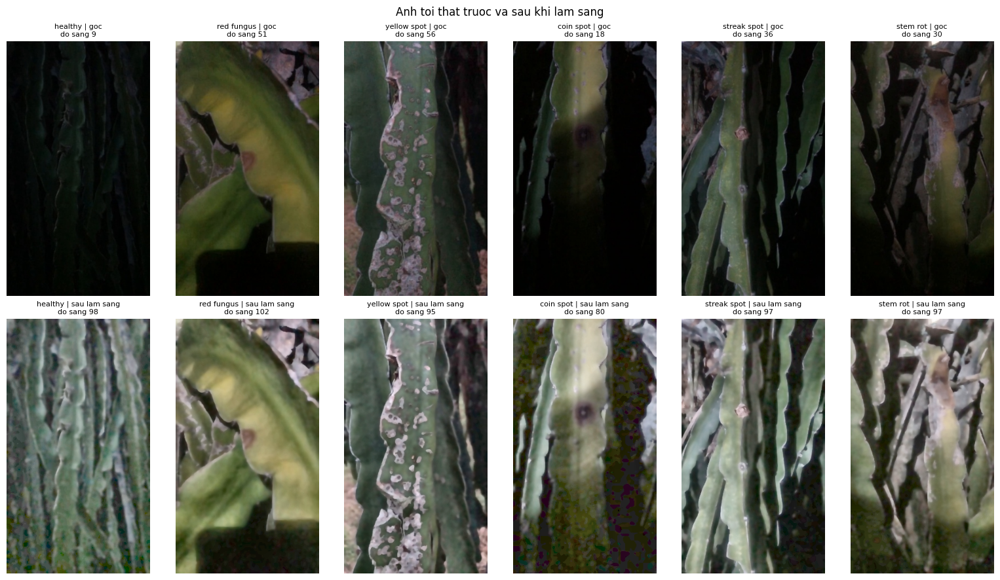

In [ ]:
# lam sang anh toi: dung chung cho train, test va web
NGUONG_TOI = 60      # do sang trung binh (0-255) duoi muc nay thi coi la anh toi
def khu_nhieu(img):
    return Image.fromarray(cv2.bilateralFilter(np.asarray(img.convert('RGB')), 7, 40, 7))

def chinh_gamma(img, muc_tieu=0.35):
    a = np.asarray(img.convert('RGB')).astype(np.float32) / 255
    tb = max(a.mean(), 1e-3)
    gamma = np.clip(np.log(muc_tieu) / np.log(tb), 0.3, 1.0) if tb < muc_tieu else 1.0
    return Image.fromarray((np.power(a, gamma) * 255).clip(0, 255).astype(np.uint8))

def clahe(img, clip=2.0, o=8):
    lab = cv2.cvtColor(np.asarray(img.convert('RGB')), cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(o, o)).apply(lab[..., 0])
    return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))

def lam_sang(img):
    return clahe(chinh_gamma(khu_nhieu(img)))

def la_anh_toi(img):
    return np.asarray(img.convert('L')).mean() < NGUONG_TOI

def tien_xu_ly_toi(img):
    img = img.convert('RGB')
    return lam_sang(img) if la_anh_toi(img) else img

class TienXuLyToi:
    def __call__(self, img):
        return tien_xu_ly_toi(img)

# anh toi that cua tung lop: truoc va sau khi lam sang
mau = data_tl[data_tl.toi & (data_tl.tap == 'train')].groupby('lop').head(1)
fig, ax = plt.subplots(2, len(mau), figsize=(2.6 * len(mau), 9))
for c, (_, row) in enumerate(mau.iterrows()):
    goc = Image.open(row['path256']).convert('RGB')
    for r, (ten, im) in enumerate([('goc', goc), ('sau lam sang', tien_xu_ly_toi(goc))]):
        ax[r, c].imshow(im)
        ax[r, c].set_title(f"{row['lop'].replace('Dragon fruit ', '')} | {ten}\ndo sang {np.asarray(im.convert('L')).mean():.0f}", fontsize=8)
        ax[r, c].axis('off')
plt.suptitle('Anh toi that truoc va sau khi lam sang')
plt.tight_layout()
plt.show()

Train: 3786 | Val: 675 | Test: 734 | So lop: 33


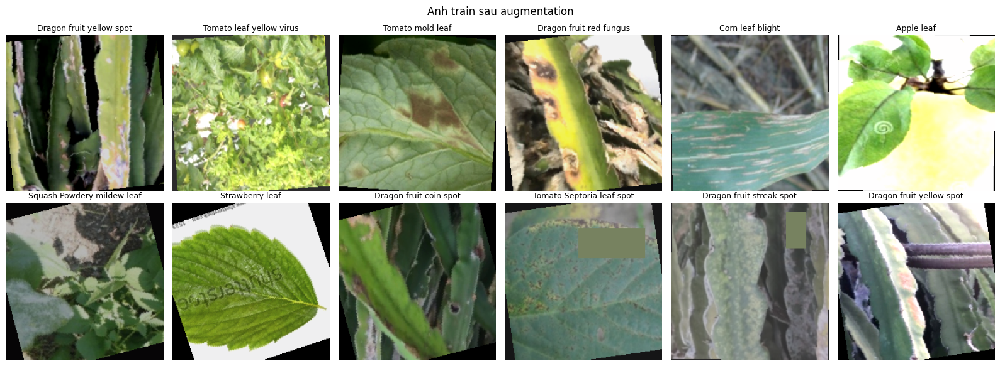

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMAGE_SIZE, BATCH_SIZE = 224, 32

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.25, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.03),
    TienXuLyToi(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])
test_tf = transforms.Compose([
    TienXuLyToi(),
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
# chi dung o muc 6 de so sanh: bo buoc lam sang
test_tf_khong_lam_sang = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class AnhDataset(Dataset):
    def __init__(self, df, tf):
        self.paths, self.nhan, self.tf = df['path256'].tolist(), df['nhan'].tolist(), tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            img = im.convert('RGB')
        return self.tf(img), self.nhan[i]

df_train = data_tl[data_tl.tap == 'train'].reset_index(drop=True)
df_val = data_tl[data_tl.tap == 'val'].reset_index(drop=True)
df_test = data_tl[data_tl.tap == 'test'].reset_index(drop=True)

train_loader = DataLoader(AnhDataset(df_train, train_tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
val_loader = DataLoader(AnhDataset(df_val, test_tf), batch_size=64, num_workers=2, pin_memory=True)
test_loader = DataLoader(AnhDataset(df_test, test_tf), batch_size=64, num_workers=2, pin_memory=True)
print('Train:', len(df_train), '| Val:', len(df_val), '| Test:', len(df_test), '| So lop:', len(LOP_ALL))

x, y = next(iter(train_loader))
hien = (x[:12].permute(0, 2, 3, 1).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)
fig, ax = plt.subplots(2, 6, figsize=(16, 6))
for a, img, nh in zip(ax.ravel(), hien, y[:12]):
    a.imshow(img)
    a.set_title(LOP_ALL[nh], fontsize=9)
    a.axis('off')
plt.suptitle('Anh train sau augmentation')
plt.tight_layout()
plt.show()

## 3. Mô hình 1: Random Forest

Random Forest không nhận ảnh trực tiếp được, nên nhóm em tự trích 154 đặc trưng cho mỗi ảnh. Ảnh tối được làm sáng trước giống mục 2, rồi thu nhỏ về 128x128:
- Đặc trưng màu: histogram HSV chia 8 x 4 x 4 = 128 ô, thêm trung bình và độ lệch chuẩn của 3 kênh H, S, V. Vết bệnh trên cành thường có màu vàng, cam, nâu hoặc trắng xám, khác với màu xanh của cành khỏe
- Đặc trưng kết cấu: histogram LBP (10 giá trị) và 5 chỉ số GLCM (contrast, dissimilarity, homogeneity, energy, correlation) ở khoảng cách 1 và 3 pixel, vì chỗ bị bệnh thường sần sùi, loang lổ



In [ ]:
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops

def dac_trung_anh(img):
    img = np.asarray(img.convert('RGB').resize((128, 128)))
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256]).flatten()
    hist = hist / hist.sum()
    mau = np.concatenate([hsv.reshape(-1, 3).mean(0), hsv.reshape(-1, 3).std(0)])
    xam = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    lbp = local_binary_pattern(xam, P=8, R=1, method='uniform')
    lbp_hist = np.histogram(lbp, bins=10, range=(0, 10))[0] / lbp.size
    glcm = graycomatrix(xam // 8, distances=[1, 3], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                        levels=32, symmetric=True, normed=True)
    tex = np.concatenate([graycoprops(glcm, p).mean(axis=1)
                          for p in ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation']])
    return np.concatenate([hist, mau, lbp_hist, tex])

def dac_trung_path(p, lam_sang_toi=True):
    with Image.open(p) as im:
        im = im.convert('RGB')
        return dac_trung_anh(tien_xu_ly_toi(im) if lam_sang_toi else im)

t = time.time()
X_trval = np.array([dac_trung_path(p) for p in data_tl.loc[data_tl.tap != 'test', 'path256']])
y_trval = data_tl.loc[data_tl.tap != 'test', 'nhan'].values
X_test = np.array([dac_trung_path(p) for p in data_tl.loc[data_tl.tap == 'test', 'path256']])
y_test_rf = data_tl.loc[data_tl.tap == 'test', 'nhan'].values
print('Train + val:', X_trval.shape, '| Test:', X_test.shape, f'| {time.time() - t:.0f}s')

Train + val: (4461, 154) | Test: (734, 154) | 60s


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

t = time.time()
rf_cv = GridSearchCV(RandomForestClassifier(n_estimators=400, class_weight=dict(enumerate(class_w)), random_state=SEED, n_jobs=-1),
                     {'max_features': ['sqrt', 0.3], 'min_samples_leaf': [1, 3]},
                     cv=PredefinedSplit(np.where(data_tl.loc[data_tl.tap != 'test', 'tap'] == 'val', 0, -1)), scoring='f1_macro')
rf_cv.fit(X_trval, y_trval)
rf = rf_cv.best_estimator_
pred_rf = rf.predict(X_test)
print('Tham so tot nhat:', rf_cv.best_params_, f'| macro F1 tren validation: {rf_cv.best_score_:.4f} | {time.time() - t:.0f}s')
print(f'Test: accuracy {accuracy_score(y_test_rf, pred_rf):.4f}, macro F1 {f1_score(y_test_rf, pred_rf, average="macro"):.4f}')

quan_trong = pd.Series(rf.feature_importances_,
                       index=[f'hsv_{i}' for i in range(128)] + ['H_tb', 'S_tb', 'V_tb', 'H_std', 'S_std', 'V_std']
                             + [f'lbp_{i}' for i in range(10)]
                             + [f'{p}_d{d}' for p in ['contrast', 'dissim', 'homo', 'energy', 'corr'] for d in [1, 3]])
print('\n10 dac trung quan trong nhat:')
print(quan_trong.sort_values(ascending=False).head(10).round(4))

Tham so tot nhat: {'max_features': 0.3, 'min_samples_leaf': 1} | macro F1 tren validation: 0.3918 | 129s
Test: accuracy 0.4332, macro F1 0.2943

10 dac trung quan trong nhat:
lbp_2      0.0202
lbp_6      0.0189
hsv_22     0.0162
hsv_6      0.0157
hsv_42     0.0155
S_std      0.0153
lbp_4      0.0150
hsv_21     0.0146
corr_d3    0.0144
hsv_37     0.0141
dtype: float64


## 4. Hai mô hình học sâu (train từ đầu)

Cả 2 mạng đều khởi tạo trọng số ngẫu nhiên, không dùng trọng số đã học trên ImageNet

- CNN tự xây: gồm 5 khối, mỗi khối có 2 lớp tích chập 3x3 (kèm BatchNorm và ReLU) rồi MaxPool để giảm kích thước đi một nửa. Số kênh qua các khối lần lượt là 32, 64, 128, 256, 256. Phía sau là Global Average Pooling, Dropout 0.4 và 1 lớp Linear ra 33 lớp. Tổng khoảng 2.4 triệu tham số
- ResNet18 (weights=None): lấy kiến trúc ResNet18 có sẵn trong torchvision nhưng không nạp trọng số. Mạng này sâu hơn (18 lớp) và có kết nối tắt (skip connection), nhờ vậy mạng sâu vẫn học được bình thường. Khoảng 11.2 triệu tham số

Để so sánh cho công bằng thì 2 mạng train cùng một cách: AdamW, OneCycleLR, label smoothing 0.1, có trọng số lớp, 40 epoch. Hết mỗi epoch thì đánh giá trên validation, cuối cùng giữ lại epoch có macro F1 cao nhất

In [ ]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models

class CNNTuXay(nn.Module):
    def __init__(self, so_lop):
        super().__init__()
        def khoi(vao, ra):
            return nn.Sequential(
                nn.Conv2d(vao, ra, 3, padding=1, bias=False), nn.BatchNorm2d(ra), nn.ReLU(inplace=True),
                nn.Conv2d(ra, ra, 3, padding=1, bias=False), nn.BatchNorm2d(ra), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(khoi(3, 32), khoi(32, 64), khoi(64, 128), khoi(128, 256), khoi(256, 256))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, so_lop))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def tao_resnet18(so_lop):
    return models.resnet18(weights=None, num_classes=so_lop)

for ten, m in [('CNN tu xay', CNNTuXay(len(LOP_ALL))), ('ResNet18', tao_resnet18(len(LOP_ALL)))]:
    print(f'{ten}: {sum(p.numel() for p in m.parameters()):,} tham so')

CNN tu xay: 2,362,369 tham so
ResNet18: 11,193,441 tham so


In [ ]:
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_w, dtype=torch.float32).to(device), label_smoothing=0.1)
dung_amp = torch.cuda.is_available()

@torch.no_grad()
def du_doan(model, loader):
    model.eval()
    ys, ps, probs = [], [], []
    for x, y in loader:
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=dung_amp):
            out = model(x.to(device, non_blocking=True))
        pr = torch.softmax(out.float(), 1).cpu()
        ys.append(y); ps.append(pr.argmax(1)); probs.append(pr)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()

def huan_luyen(model, ten, so_epoch=35, lr=2e-3):
    model = model.to(device)
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=so_epoch, steps_per_epoch=len(train_loader))
    scaler = torch.amp.GradScaler('cuda', enabled=dung_amp)
    best_f1, best_state, lich_su = -1, None, []
    t0 = time.time()
    for ep in range(1, so_epoch + 1):
        model.train()
        tong_loss, dung, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=dung_amp):
                out = model(x)
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sch.step()
            tong_loss += loss.item() * len(y); dung += (out.argmax(1) == y).sum().item(); n += len(y)
        yv, pv, prv = du_doan(model, val_loader)
        va_loss = nn.functional.nll_loss(torch.log(torch.tensor(prv) + 1e-8), torch.tensor(yv)).item()
        va_acc, va_f1 = accuracy_score(yv, pv), f1_score(yv, pv, average='macro')
        lich_su.append([ep, tong_loss / n, dung / n, va_loss, va_acc, va_f1])
        ghi = ''
        if va_f1 > best_f1:
            best_f1, best_state, ghi = va_f1, copy.deepcopy(model.state_dict()), ' <- tot nhat'
        if ep % 5 == 0 or ghi or ep == 1:
            print(f'[{ten}] epoch {ep:2d}/{so_epoch} | train loss {tong_loss / n:.4f} acc {dung / n:.2%} | '
                  f'val loss {va_loss:.4f} acc {va_acc:.2%} macro F1 {va_f1:.4f}{ghi}')
    model.load_state_dict(best_state)
    print(f'[{ten}] xong sau {time.time() - t0:.0f}s, val macro F1 tot nhat {best_f1:.4f}')
    return model, pd.DataFrame(lich_su, columns=['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_f1'])

In [ ]:
SO_EPOCH = 40
cnn, ls_cnn = huan_luyen(CNNTuXay(len(LOP_ALL)), 'CNN', so_epoch=SO_EPOCH)

[CNN] epoch  1/40 | train loss 3.4516 acc 14.96% | val loss 2.5332 acc 32.89% macro F1 0.1302 <- tot nhat
[CNN] epoch  2/40 | train loss 3.1781 acc 25.45% | val loss 2.4473 acc 34.37% macro F1 0.1423 <- tot nhat
[CNN] epoch  4/40 | train loss 3.0220 acc 32.26% | val loss 2.1708 acc 40.89% macro F1 0.1639 <- tot nhat
[CNN] epoch  5/40 | train loss 3.0051 acc 32.39% | val loss 2.4852 acc 27.56% macro F1 0.1006
[CNN] epoch  6/40 | train loss 2.9767 acc 33.87% | val loss 2.1354 acc 38.37% macro F1 0.1771 <- tot nhat
[CNN] epoch  7/40 | train loss 2.9194 acc 36.33% | val loss 1.9385 acc 44.30% macro F1 0.1951 <- tot nhat
[CNN] epoch 10/40 | train loss 2.8148 acc 39.72% | val loss 1.8297 acc 50.07% macro F1 0.1878
[CNN] epoch 11/40 | train loss 2.7665 acc 40.92% | val loss 1.8602 acc 48.30% macro F1 0.2124 <- tot nhat
[CNN] epoch 12/40 | train loss 2.7222 acc 42.03% | val loss 1.8290 acc 48.74% macro F1 0.2523 <- tot nhat
[CNN] epoch 13/40 | train loss 2.6907 acc 43.96% | val loss 1.7978 acc

In [ ]:
resnet, ls_resnet = huan_luyen(tao_resnet18(len(LOP_ALL)), 'ResNet18', so_epoch=SO_EPOCH)

[ResNet18] epoch  1/40 | train loss 3.3714 acc 17.74% | val loss 2.3572 acc 29.93% macro F1 0.1194 <- tot nhat
[ResNet18] epoch  2/40 | train loss 3.0985 acc 28.60% | val loss 2.2599 acc 37.63% macro F1 0.1402 <- tot nhat
[ResNet18] epoch  3/40 | train loss 3.0280 acc 31.38% | val loss 2.0986 acc 40.74% macro F1 0.1607 <- tot nhat
[ResNet18] epoch  5/40 | train loss 2.9697 acc 34.00% | val loss 2.1955 acc 40.30% macro F1 0.1536
[ResNet18] epoch  8/40 | train loss 2.8909 acc 37.79% | val loss 2.3220 acc 36.89% macro F1 0.1948 <- tot nhat
[ResNet18] epoch  9/40 | train loss 2.8452 acc 39.09% | val loss 1.8875 acc 48.00% macro F1 0.2320 <- tot nhat
[ResNet18] epoch 10/40 | train loss 2.7818 acc 41.34% | val loss 2.1585 acc 40.15% macro F1 0.2351 <- tot nhat
[ResNet18] epoch 13/40 | train loss 2.6385 acc 46.13% | val loss 1.8472 acc 47.85% macro F1 0.2549 <- tot nhat
[ResNet18] epoch 14/40 | train loss 2.5902 acc 48.28% | val loss 1.8054 acc 46.52% macro F1 0.2552 <- tot nhat
[ResNet18] ep

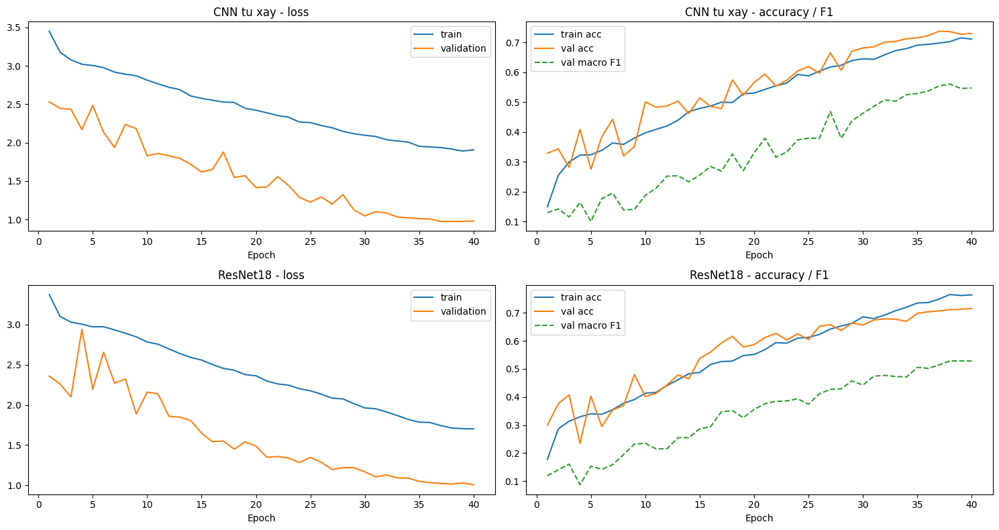

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
for r, (ten, ls) in enumerate([('CNN tu xay', ls_cnn), ('ResNet18', ls_resnet)]):
    ax[r, 0].plot(ls['epoch'], ls['train_loss'], label='train')
    ax[r, 0].plot(ls['epoch'], ls['val_loss'], label='validation')
    ax[r, 0].set_title(f'{ten} - loss')
    ax[r, 1].plot(ls['epoch'], ls['train_acc'], label='train acc')
    ax[r, 1].plot(ls['epoch'], ls['val_acc'], label='val acc')
    ax[r, 1].plot(ls['epoch'], ls['val_f1'], label='val macro F1', linestyle='--')
    ax[r, 1].set_title(f'{ten} - accuracy / F1')
    for a in ax[r]:
        a.set_xlabel('Epoch')
        a.legend()
plt.tight_layout()
plt.show()

Nhận xét:


- Val macro F1 cao nhất của CNN là 0.5605 ở epoch 38, của ResNet18 là 0.5286 ở epoch 39. Trên validation thì CNN nhỉnh hơn một chút
- Cả 2 mạng đều chưa học xong. Tới epoch 40 train accuracy mới có 71.11% (CNN) và 76.38% (ResNet18), loss train và loss validation đều vẫn đang giảm, epoch tốt nhất thì nằm sát cuối. Tức là mô hình đang underfit chứ chưa bị overfit. Có tới 33 lớp, mạng lại phải học từ đầu, thêm augmentation khá mạnh nên 40 epoch là chưa đủ
- Loss validation thấp hơn loss train suốt cả quá trình. Lúc train ảnh bị cắt nhỏ, bị xóa mảng, có label smoothing và dropout, còn lúc đánh giá thì không có mấy thứ này nên loss validation thấp hơn là bình thường
- Khoảng 10 epoch đầu đường validation nhảy lên xuống khá mạnh, ví dụ ResNet18 ở epoch 4 có val loss vọt lên gần 3.0. Giai đoạn này learning rate của OneCycleLR đang tăng dần, từ khoảng epoch 15 trở đi thì đường ổn định hơn

## 5. Đánh giá trên tập test

In [ ]:
y_test, pred_cnn, prob_cnn = du_doan(cnn, test_loader)
_, pred_resnet, prob_resnet = du_doan(resnet, test_loader)
assert (y_test == y_test_rf).all()

def chi_so(y, p, mask=None):
    if mask is not None:
        y, p = y[mask], p[mask]
    return [accuracy_score(y, p), precision_score(y, p, average='macro', zero_division=0),
            recall_score(y, p, average='macro', zero_division=0), f1_score(y, p, average='macro', zero_division=0)]

ID_TL = [NHAN[l] for l in LOP_TL]
ID_PD = [NHAN[l] for l in LOP_PD]
la_tl = np.isin(y_test, ID_TL)
la_toi = df_test['toi'].values.astype(bool)

def f1_nhom(y, p, ids):
    return f1_score(y, p, labels=ids, average='macro', zero_division=0)

MO_HINH = [('Random Forest', pred_rf), ('CNN tu xay', pred_cnn), ('ResNet18', pred_resnet)]
ket_qua = pd.DataFrame(
    [[ten] + chi_so(y_test, p)
     + [accuracy_score(y_test[la_tl], p[la_tl]), f1_nhom(y_test, p, ID_TL),
        accuracy_score(y_test[la_tl & ~la_toi], p[la_tl & ~la_toi]), accuracy_score(y_test[la_toi], p[la_toi]),
        accuracy_score(y_test[~la_tl], p[~la_tl]), f1_nhom(y_test, p, ID_PD),
        int(np.isin(p[la_tl], ID_PD).sum()), int(np.isin(p[~la_tl], ID_TL).sum())]
     for ten, p in MO_HINH],
    columns=['Mo hinh', 'Accuracy', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)',
             'Acc thanh long', 'F1 thanh long', 'Acc TL sang', 'Acc TL toi', 'Acc PlantDoc', 'F1 PlantDoc', 'TL doan thanh PD', 'PD doan thanh TL']
).set_index('Mo hinh')
print('Test:', la_tl.sum(), 'anh thanh long (', (la_tl & ~la_toi).sum(), 'sang,', la_toi.sum(), 'toi ),', (~la_tl).sum(), 'anh PlantDoc')
ket_qua.round(4)

Test: 509 anh thanh long ( 301 sang, 208 toi ), 225 anh PlantDoc


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Acc thanh long,F1 thanh long,Acc TL sang,Acc TL toi,Acc PlantDoc,F1 PlantDoc,TL doan thanh PD,PD doan thanh TL
Mo hinh,,,,,,,,,,,,
Random Forest,0.4332,0.3416,0.3251,0.2943,0.5128,0.6082,0.5880,0.4038,0.2533,0.2245,96,8
CNN tu xay,0.5436,0.4572,0.4975,0.4327,0.5874,0.6427,0.6312,0.5240,0.4444,0.3860,41,2
ResNet18,0.5817,0.4521,0.4981,0.4471,0.6424,0.7221,0.7409,0.5000,0.4444,0.3860,43,1


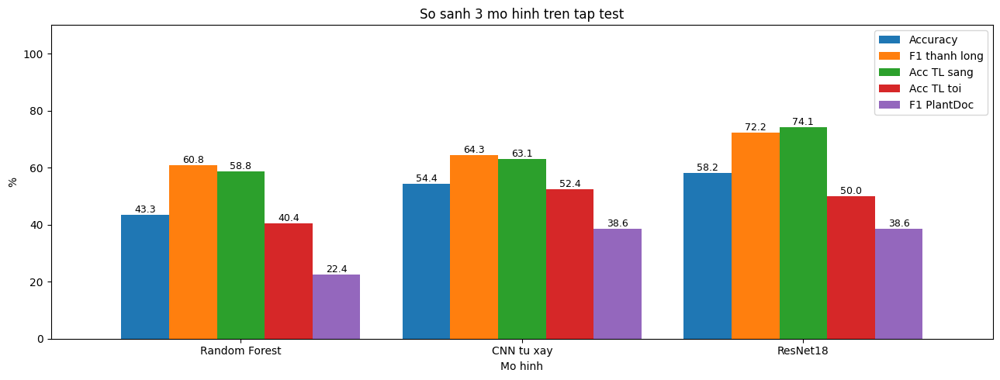

Mo hinh tot nhat theo macro F1: ResNet18 | mo hinh hoc sau tot hon, dung cho web: ResNet18


In [ ]:
ax = ket_qua[['Accuracy', 'F1 thanh long', 'Acc TL sang', 'Acc TL toi', 'F1 PlantDoc']].mul(100).plot(kind='bar', figsize=(13, 5), width=0.85)
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', fontsize=9)
plt.ylim(0, 110)
plt.ylabel('%')
plt.xticks(rotation=0)
plt.title('So sanh 3 mo hinh tren tap test')
plt.tight_layout()
plt.show()

TOT_NHAT = ket_qua['F1 (macro)'].idxmax()
TEN_MODEL = 'ResNet18' if ket_qua.loc['ResNet18', 'F1 (macro)'] >= ket_qua.loc['CNN tu xay', 'F1 (macro)'] else 'CNN tu xay'
model_tot = resnet if TEN_MODEL == 'ResNet18' else cnn
pred_tot = pred_resnet if TEN_MODEL == 'ResNet18' else pred_cnn
print('Mo hinh tot nhat theo macro F1:', TOT_NHAT, '| mo hinh hoc sau tot hon, dung cho web:', TEN_MODEL)

                            precision    recall  f1-score   support

      Dragon fruit healthy      0.900     0.351     0.505       154
   Dragon fruit red fungus      0.957     1.000     0.978        22
  Dragon fruit yellow spot      0.620     0.360     0.456        86
    Dragon fruit coin spot      0.652     1.000     0.789        73
  Dragon fruit streak spot      0.628     0.825     0.713       143
     Dragon fruit stem rot      0.853     0.935     0.892        31
           Apple Scab Leaf      0.333     0.300     0.316        10
                Apple leaf      0.467     0.778     0.583         9
           Apple rust leaf      0.417     0.500     0.455        10
          Bell_pepper leaf      0.333     0.125     0.182         8
     Bell_pepper leaf spot      0.250     0.111     0.154         9
            Blueberry leaf      0.500     0.200     0.286        10
               Cherry leaf      0.231     0.300     0.261        10
       Corn Gray leaf spot      0.143     0.333

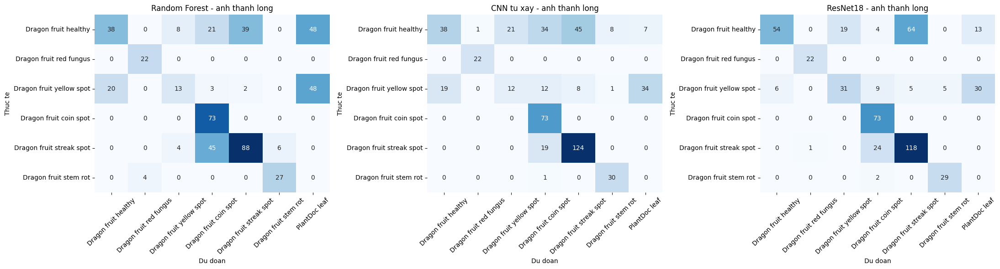

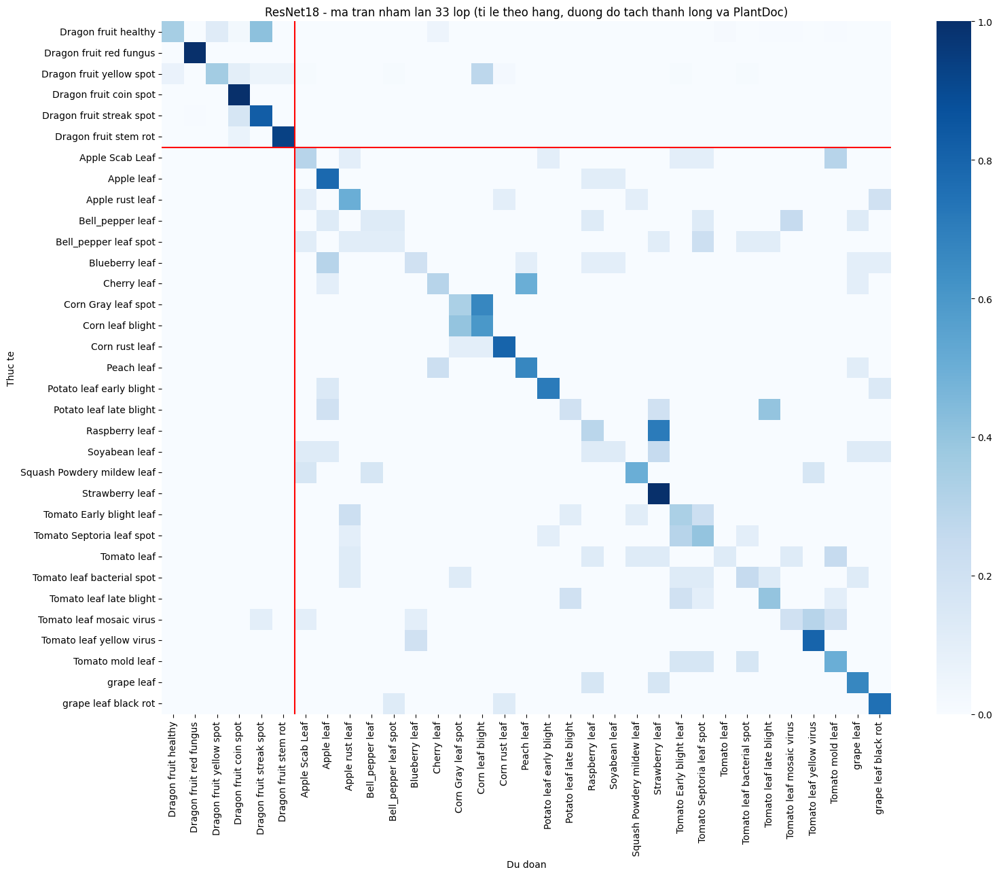

Cac cap lop hay nham nhat:
                 Thuc te               Doan thanh  So anh
    Dragon fruit healthy Dragon fruit streak spot      64
Dragon fruit yellow spot         Corn leaf blight      24
Dragon fruit streak spot   Dragon fruit coin spot      24
    Dragon fruit healthy Dragon fruit yellow spot      19
Dragon fruit yellow spot   Dragon fruit coin spot       9
    Dragon fruit healthy              Cherry leaf       8
Dragon fruit yellow spot     Dragon fruit healthy       6
Dragon fruit yellow spot Dragon fruit streak spot       5
Dragon fruit yellow spot    Dragon fruit stem rot       5
             Cherry leaf               Peach leaf       5
          Raspberry leaf          Strawberry leaf       5
    Dragon fruit healthy   Dragon fruit coin spot       4


In [ ]:
print(classification_report(y_test, pred_tot, labels=range(len(LOP_ALL)),
                            target_names=LOP_ALL, digits=3, zero_division=0))

# ma tran nham lan phan thanh long: 6 lop thanh long, cac lop PlantDoc gop thanh 1 cot
TEN_COT = list(LOP_TL) + ['PlantDoc leaf']
def gop_pd(p):
    return np.where(np.isin(p, ID_TL), p, len(LOP_TL))

fig, ax = plt.subplots(1, 3, figsize=(22, 6))
for a, (ten, p) in zip(ax, MO_HINH):
    cm = confusion_matrix(y_test[la_tl], gop_pd(p[la_tl]), labels=range(len(LOP_TL) + 1))[:len(LOP_TL)]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=TEN_COT, yticklabels=TEN_COT[:-1])
    a.set_title(f'{ten} - anh thanh long')
    a.set_xlabel('Du doan'); a.set_ylabel('Thuc te')
    a.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# ma tran day du 33 lop cua mo hinh tot nhat (ti le theo hang)
cm = confusion_matrix(y_test, pred_tot, labels=range(len(LOP_ALL)))
plt.figure(figsize=(16, 13))
sns.heatmap(cm / cm.sum(1, keepdims=True).clip(min=1), cmap='Blues', vmin=0, vmax=1,
            xticklabels=LOP_ALL, yticklabels=LOP_ALL)
plt.axhline(len(LOP_TL), color='red'); plt.axvline(len(LOP_TL), color='red')
plt.title(f'{TEN_MODEL} - ma tran nham lan 33 lop (ti le theo hang, duong do tach thanh long va PlantDoc)')
plt.xlabel('Du doan'); plt.ylabel('Thuc te')
plt.tight_layout()
plt.show()

nham = [(LOP_ALL[i], LOP_ALL[j], cm[i, j]) for i in range(len(LOP_ALL)) for j in range(len(LOP_ALL)) if i != j and cm[i, j] > 0]
print('Cac cap lop hay nham nhat:')
print(pd.DataFrame(nham, columns=['Thuc te', 'Doan thanh', 'So anh']).sort_values('So anh', ascending=False).head(12).to_string(index=False))

In [ ]:

dt = df_test.copy()
dt['dung_rf'] = pred_rf == y_test
dt['dung_cnn'] = pred_cnn == y_test
dt['dung_resnet'] = pred_resnet == y_test
video_train = set(data_tl.loc[data_tl.tap != 'test', 'video'])
dt['cach_chia'] = np.where(~dt['lop'].isin(LOP_TL), 'anh PlantDoc',
                  np.where(~dt['video'].isin(video_train), 'video rieng', 'doan cuoi video'))
dtl = dt[dt.lop.isin(LOP_TL)]
nhom = ['lop', 'video', 'loai', 'cach_chia']
theo_video = dtl.groupby(nhom)[['dung_rf', 'dung_cnn', 'dung_resnet']].mean().mul(100).round(1)
theo_video['so_anh'] = dtl.groupby(nhom).size()
print(theo_video.to_string())
print()
print(dt.groupby(['loai', 'cach_chia'])[['dung_rf', 'dung_cnn', 'dung_resnet']].mean().mul(100).round(1))

                                                           dung_rf  dung_cnn  dung_resnet  so_anh
lop                      video       loai cach_chia                                              
Dragon fruit coin spot   thanhlong19 toi  doan cuoi video    100.0     100.0        100.0      12
                         thanhlong8  sang doan cuoi video    100.0     100.0        100.0      61
Dragon fruit healthy     thanhlong13 toi  video rieng         13.8       1.2          3.8      80
                         thanhlong9  sang video rieng         36.5      50.0         68.9      74
Dragon fruit red fungus  thanhlong17 toi  doan cuoi video    100.0     100.0        100.0      12
                         thanhlong2  sang doan cuoi video    100.0     100.0        100.0      10
Dragon fruit stem rot    thanhlong16 toi  doan cuoi video    100.0      91.7         83.3      12
                         thanhlong3  sang doan cuoi video     78.9     100.0        100.0      19
Dragon fruit streak 

Nhận xét:

- Trên toàn tập test, ResNet18 tốt nhất với accuracy 58.17% và macro F1 0.4471, tiếp theo là CNN tự xây (54.36%, 0.4327), Random Forest thấp nhất (43.32%, 0.2943). Trên validation thì CNN cao hơn, nhưng ở những video sáng chưa thấy bao giờ ResNet18 đúng 47.3% còn CNN chỉ 25.0%, nên nhóm em chọn ResNet18 để đưa lên web
- Phần thanh long, ResNet18 đúng 64.24% (F1 0.7221). Ảnh sáng đúng 74.09%, ảnh tối chỉ 50.00%. Riêng ảnh tối thì CNN được 52.40%, cao hơn ResNet18 một chút
- So với lần chạy trước khi chưa train ảnh tối, ResNet18 tăng accuracy từ 56.08% lên 58.17% và macro F1 từ 0.3932 lên 0.4471. Ảnh thanh long sáng lần trước đúng 70.76%, lần này 74.09%
- Phần PlantDoc chỉ đúng khoảng 44% với cả 2 mạng học sâu, Random Forest được 25.33%. Mỗi lớp PlantDoc có ít ảnh, nhiều lớp lại là cùng 1 loại cây và chỉ khác nhau ở vết bệnh, ví dụ Corn Gray leaf spot với Corn leaf blight, Raspberry leaf với Strawberry leaf
- Mô hình rất ít khi đoán lá PlantDoc thành thanh long (ResNet18 chỉ có 1 ảnh). Chiều ngược lại thì nhiều hơn, 43 ảnh thanh long bị đoán thành lá PlantDoc, trong đó 30 ảnh là đốm vàng ở video thanhlong10 và 13 ảnh là khỏe mạnh ở video tối thanhlong13
- Bảng theo video cho thấy rõ ảnh hưởng của cách chia dữ liệu. Các lớp test bằng đoạn cuối video thì cả 3 mô hình đúng gần 100%, kể cả ảnh tối. Còn ở video chưa thấy bao giờ thì thấp hơn hẳn: ResNet18 đúng 68.9% ở thanhlong9 (khỏe mạnh, sáng), 25.7% ở thanhlong10 (đốm vàng, sáng), 68.8% ở thanhlong18 (đốm dây, tối) và chỉ 3.8% ở thanhlong13 (khỏe mạnh, tối). Con số gần 100% kia phần lớn là do mô hình nhớ cảnh, con số ở video riêng mới gần với lúc dùng thật
- Mấy cặp nhầm nhiều nhất: khỏe mạnh bị đoán thành đốm dây 64 ảnh (toàn bộ đều thuộc video tối thanhlong13), đốm vàng thành Corn leaf blight 24 ảnh, đốm dây thành nấm đồng tiền 24 ảnh (đều thuộc video tối thanhlong18)
- Random Forest kém nhất, rõ nhất là ở video sáng chưa thấy bao giờ (chỉ 18.9%). Đặc trưng màu và kết cấu tự trích có lẽ chỉ bắt được kiểu nền và ánh sáng của từng video, sang cảnh khác là không nhận ra vết bệnh nữa

## 6. Bước làm sáng ảnh tối
Ảnh tối trong tập test gồm 2 video mô hình chưa thấy lúc train (thanhlong13 khỏe mạnh, thanhlong18 đốm dây) và đoạn cuối của 4 video tối còn lại, tổng cộng 208 ảnh. Để xem bước làm sáng có cần thật không, nhóm em cho 3 mô hình đoán lại đúng 208 ảnh này nhưng bỏ bước làm sáng đi (đưa thẳng ảnh tối vào mô hình), rồi so với lúc có làm sáng

In [ ]:
df_test_toi = df_test[la_toi].reset_index(drop=True)
loader_khong = DataLoader(AnhDataset(df_test_toi, test_tf_khong_lam_sang), batch_size=64, num_workers=2)
y_toi, p_cnn_k, _ = du_doan(cnn, loader_khong)
_, p_res_k, _ = du_doan(resnet, loader_khong)
p_rf_k = rf.predict(np.array([dac_trung_path(p, lam_sang_toi=False) for p in df_test_toi['path256']]))

kq_toi = pd.DataFrame({
    'Co lam sang': [accuracy_score(y_test[la_toi], p[la_toi]) for p in [pred_rf, pred_cnn, pred_resnet]],
    'Khong lam sang': [accuracy_score(y_toi, p) for p in [p_rf_k, p_cnn_k, p_res_k]],
}, index=['Random Forest', 'CNN tu xay', 'ResNet18'])
kq_toi.index.name = 'Mo hinh'
print(f'Accuracy tren {len(y_toi)} anh toi cua tap test:')
print(kq_toi.round(4))

p_tot_k = p_res_k if TEN_MODEL == 'ResNet18' else p_cnn_k
bang_v = pd.DataFrame({
    'so_anh': df_test_toi.groupby('video').size(),
    'lop': df_test_toi.groupby('video')['lop'].first(),
    'cach_chia': df_test_toi.groupby('video')['video'].first().map(lambda v: 'video rieng' if v not in video_train else 'doan cuoi video'),
    'co lam sang (%)': pd.Series(pred_tot[la_toi] == y_toi).groupby(df_test_toi['video']).mean().mul(100).round(1),
    'khong lam sang (%)': pd.Series(p_tot_k == y_toi).groupby(df_test_toi['video']).mean().mul(100).round(1),
})
print(f'\nTheo tung video toi ({TEN_MODEL}):')
print(bang_v.to_string())

Accuracy tren 208 anh toi cua tap test:
               Co lam sang  Khong lam sang
Mo hinh                                   
Random Forest       0.4038          0.3173
CNN tu xay          0.5240          0.5144
ResNet18            0.5000          0.5288

Theo tung video toi (ResNet18):
             so_anh                       lop        cach_chia  co lam sang (%)  khong lam sang (%)
video                                                                                              
thanhlong13      80      Dragon fruit healthy      video rieng              3.8                 7.5
thanhlong15      12  Dragon fruit yellow spot  doan cuoi video            100.0               100.0
thanhlong16      12     Dragon fruit stem rot  doan cuoi video             83.3                75.0
thanhlong17      12   Dragon fruit red fungus  doan cuoi video            100.0               100.0
thanhlong18      80  Dragon fruit streak spot      video rieng             68.8                88.8
thanhlong19 

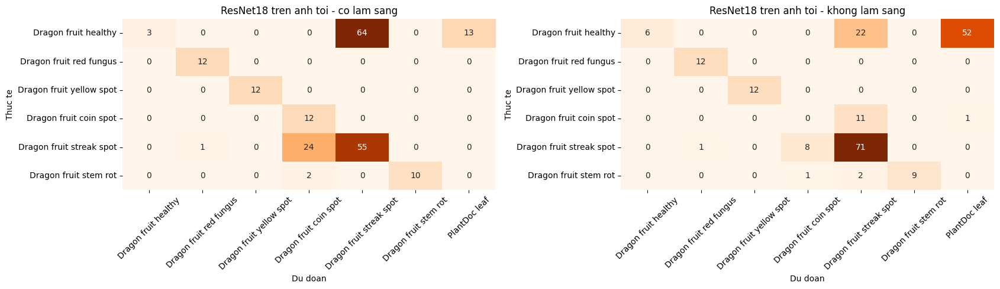

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
for a, (ten, p) in zip(ax, [('co lam sang', pred_tot[la_toi]), ('khong lam sang', p_tot_k)]):
    hang = sorted(set(y_toi))
    cm = confusion_matrix(y_toi, gop_pd(p), labels=range(len(LOP_TL) + 1))[hang]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=a,
                xticklabels=TEN_COT, yticklabels=[TEN_COT[h] for h in hang])
    a.set_title(f'{TEN_MODEL} tren anh toi - {ten}')
    a.set_xlabel('Du doan'); a.set_ylabel('Thuc te')
    a.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

Nhận xét:

- Kết quả không giống như nhóm em nghĩ lúc đầu. Làm sáng giúp Random Forest rõ nhất (từ 31.73% lên 40.38%), vì đặc trưng màu của Random Forest phụ thuộc trực tiếp vào độ sáng. CNN thì gần như không khác (52.40% so với 51.44%), còn ResNet18 có làm sáng lại thấp hơn một chút (50.00% so với 52.88%)
- Xem theo từng video thì rõ hơn. Ở thanhlong19 (nấm đồng tiền), có làm sáng thì đúng 12/12 ảnh, bỏ làm sáng thì sai hết. Mô hình đã quen với ảnh tối sau khi làm sáng, đưa ảnh tối gốc vào là nó không nhận ra. Nhưng ở thanhlong18 (đốm dây) thì bỏ làm sáng lại đúng nhiều hơn (88.8% so với 68.8%). Có làm sáng thì 24 ảnh của video này bị đoán thành nấm đồng tiền, có lẽ vì sau khi làm sáng thân cành trong video này ngả vàng nhạt, nhìn giống video nấm đồng tiền tối
- thanhlong13 (khỏe mạnh) sai gần hết dù có làm sáng hay không. Có làm sáng thì 64/80 ảnh bị đoán thành đốm dây, không làm sáng thì 52 ảnh bị đoán thành lá PlantDoc. Video tối của lớp khỏe mạnh dùng để train chỉ có thanhlong12, video này tối hơn hẳn (khung mẫu ở trên có độ sáng chỉ 9), làm sáng lên thì nổi nhiễu hạt nhiều, nhìn khác xa thanhlong13. Lớp khỏe mạnh chỉ được học 1 cảnh tối nên gặp cảnh khác là không nhận ra
- Bước làm sáng vẫn phải giữ, vì mô hình đã train trên ảnh được làm sáng và web cũng làm y như vậy. Còn muốn nhận ảnh tối tốt hơn thì cái thiếu là video tối quay ở nhiều cành khác nhau, chỉ chỉnh cách làm sáng thì khó mà sửa được

## 7. Thử dự đoán vài ảnh

Nhóm em lấy ngẫu nhiên vài ảnh trong tập test để xem mô hình đoán ra sao: 6 ảnh thanh long sáng, 3 ảnh PlantDoc và 3 ảnh thanh long tối (ảnh tối được tự làm sáng trước khi đoán). Mỗi ảnh ghi 3 lớp có xác suất cao nhất, chữ xanh là đoán đúng, chữ đỏ là đoán sai

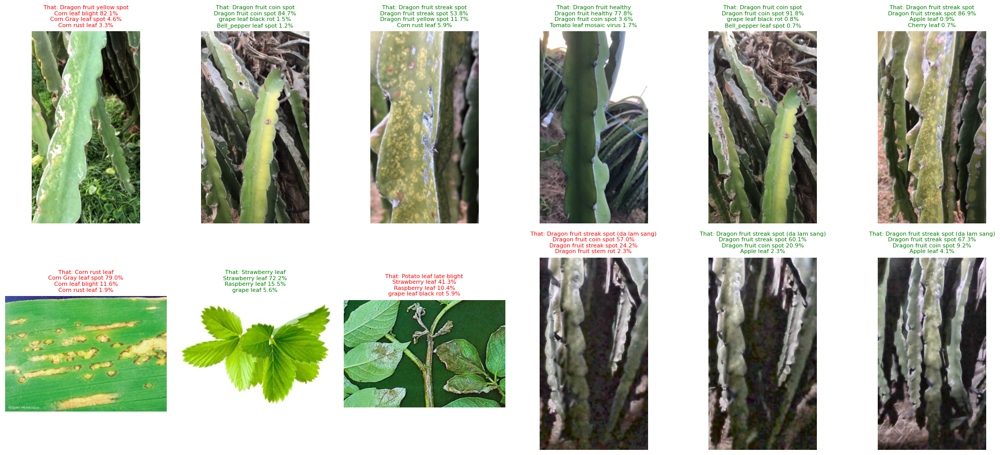

In [ ]:
@torch.no_grad()
def du_doan_anh(img, model=None, top=3):
    if model is None:
        model = model_tot
    model.eval()
    img = img.convert('RGB')
    da_lam_sang = la_anh_toi(img)
    img = tien_xu_ly_toi(img)
    prob = torch.softmax(model(test_tf_khong_lam_sang(img).unsqueeze(0).to(device)).float(), 1)[0].cpu().numpy()
    idx = prob.argsort()[::-1][:top]
    return img, [(LOP_ALL[i], float(prob[i])) for i in idx], da_lam_sang

mau = pd.concat([df_test[df_test.lop.isin(LOP_TL) & ~df_test.toi].sample(6, random_state=3),
                 df_test[df_test.lop.isin(LOP_PD)].sample(3, random_state=3),
                 df_test[df_test.toi].sample(3, random_state=3)])
fig, ax = plt.subplots(2, 6, figsize=(20, 9))
for a, (_, row) in zip(ax.ravel(), mau.iterrows()):
    img, top3, ls = du_doan_anh(Image.open(row['path256']))
    a.imshow(img)
    a.axis('off')
    dung = top3[0][0] == row['lop']
    a.set_title(f"That: {row['lop']}{' (da lam sang)' if ls else ''}\n"
                + '\n'.join(f'{c} {p:.1%}' for c, p in top3), fontsize=8, color='green' if dung else 'red')
plt.tight_layout()
plt.show()

Nhận xét:

Trong 12 ảnh, mô hình đoán đúng 8 ảnh
- 6 ảnh thanh long sáng đúng 5. Ảnh sai là đốm vàng của video thanhlong10, bị đoán thành Corn leaf blight tới 82.1%, giống lỗi hay gặp ở mục 5. Vết bệnh trong ảnh này là mấy mảng nhạt màu kéo dài theo cành, nhìn hơi giống vết cháy dài trên lá ngô
- Các ảnh nấm đồng tiền và đốm dây đúng với xác suất cao (84.7%, 91.8%, 86.9%) đều thuộc đoạn cuối của video đã dùng để train. Ảnh khỏe mạnh đúng 77.8% thì thuộc thanhlong9, video mô hình chưa thấy lần nào
- 3 ảnh PlantDoc chỉ đúng 1 (Strawberry leaf 72.2%). Corn rust leaf bị đoán thành Corn Gray leaf spot (cũng là lá ngô), còn Potato leaf late blight bị đoán thành Strawberry leaf
- 3 ảnh tối đều thuộc video thanhlong18 (đốm dây), đúng 2 ảnh với xác suất khoảng 60% đến 67%. Ảnh còn lại bị đoán thành nấm đồng tiền 57.0%, đốm dây đứng thứ 2 với 24.2%

## 8. Nhận diện từ video

Web cho người dùng tải lên cả video. Nhóm em xử lý video như sau:
- Cứ 0.5 giây lấy 1 khung hình, video dài quá thì chỉ lấy tối đa 60 khung chia đều theo thời gian
- Mỗi khung đi qua đúng các bước giống ảnh: resize cạnh ngắn về 256, làm sáng nếu khung bị tối, cắt giữa 224x224, chuẩn hóa
- Mô hình đoán từng khung, rồi lấy trung bình xác suất của tất cả các khung làm kết quả cho cả video. Cách này ổn định hơn đoán 1 ảnh, vì video nào cũng có vài khung bị mờ hoặc quay lệch ra chỗ khác

Nhóm em thử với 4 video mô hình chưa thấy lúc train: thanhlong9 (khỏe mạnh), thanhlong10 (đốm vàng), và 2 video quay lúc tối là thanhlong13 (khỏe mạnh), thanhlong18 (đốm dây)

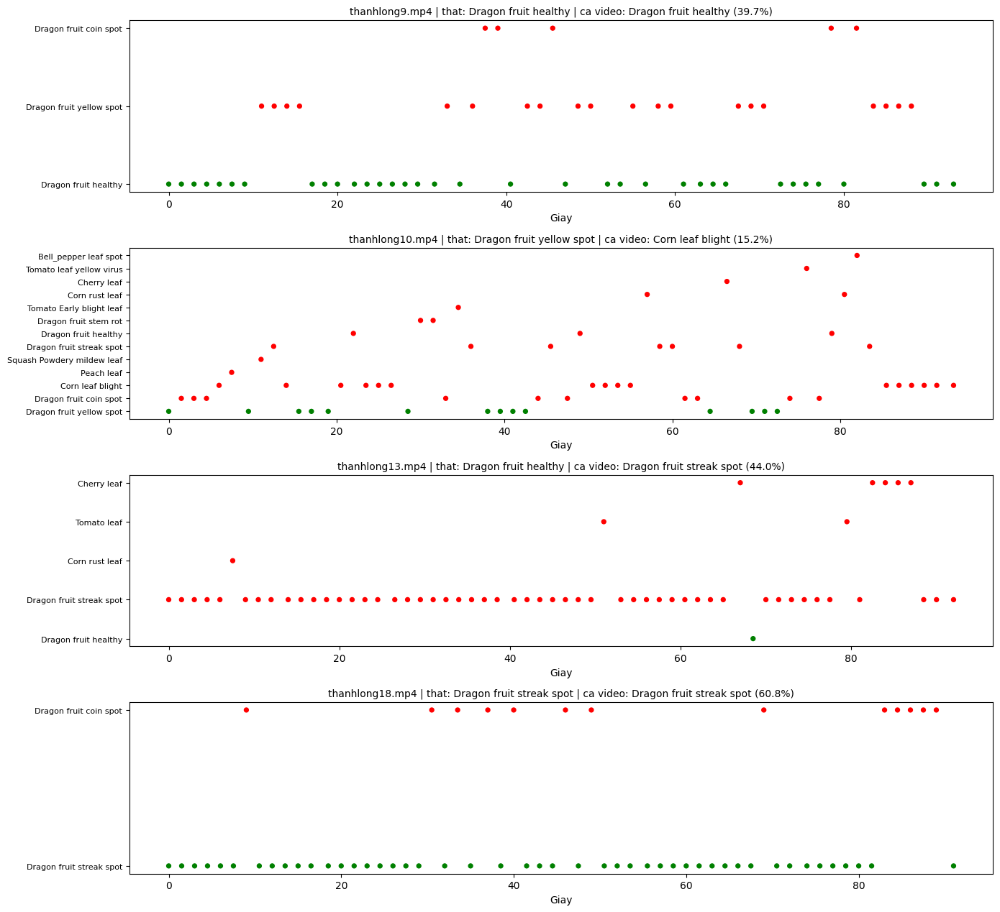

          video                     that  so_khung  % khung dung                                                                             top 3 ca video  khung lam sang  giay
 thanhlong9.mp4     Dragon fruit healthy        60          58.3    Dragon fruit healthy 39.7%, Dragon fruit yellow spot 21.3%, Dragon fruit coin spot 9.1%               0  19.1
thanhlong10.mp4 Dragon fruit yellow spot        60          23.3       Corn leaf blight 15.2%, Dragon fruit yellow spot 12.0%, Dragon fruit coin spot 10.0%               0  19.9
thanhlong13.mp4     Dragon fruit healthy        60           1.7                      Dragon fruit streak spot 44.0%, Cherry leaf 9.3%, Corn rust leaf 6.3%              60  19.2
thanhlong18.mp4 Dragon fruit streak spot        60          78.3 Dragon fruit streak spot 60.8%, Dragon fruit coin spot 20.9%, Dragon fruit red fungus 1.7%              60  19.4


In [ ]:
def resize_canh_ngan(img, canh=256):
    w, h = img.size
    tl_ = canh / min(w, h)
    return img.resize((max(canh, round(w * tl_)), max(canh, round(h * tl_))), Image.BILINEAR)

@torch.no_grad()
def du_doan_video(path, moi_giay=2, toi_da=60, model=None):
    model = model_tot if model is None else model
    model.eval()
    cap = cv2.VideoCapture(path)
    n, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS) or 30
    vi_tri = np.arange(0, max(n, 1), max(1, int(round(fps / moi_giay))))
    if len(vi_tri) > toi_da:
        vi_tri = vi_tri[np.linspace(0, len(vi_tri) - 1, toi_da).astype(int)]
    x, giay, da_ls = [], [], []
    for i in vi_tri:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ok, f = cap.read()
        if not ok:
            continue
        img = resize_canh_ngan(Image.fromarray(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)))
        toi_ = la_anh_toi(img)
        img = tien_xu_ly_toi(img)
        x.append(test_tf_khong_lam_sang(img)); giay.append(i / fps); da_ls.append(toi_)
    cap.release()
    prob = torch.softmax(model(torch.stack(x).to(device)).float(), 1).cpu().numpy()
    khung = pd.DataFrame({'giay': giay, 'lop': [LOP_ALL[k] for k in prob.argmax(1)], 'xac_suat': prob.max(1), 'da_lam_sang': da_ls})
    tb = prob.mean(0)
    return khung, [(LOP_ALL[k], float(tb[k])) for k in tb.argsort()[::-1][:3]]

VIDEO_THU = [('video_thanhlong_benh', 'thanhlong9.mp4', 'Dragon fruit healthy'),
             ('video_thanhlong_benh', 'thanhlong10.mp4', 'Dragon fruit yellow spot'),
             ('video_thanhlong_dieukientroitoi', 'thanhlong13.mp4', 'Dragon fruit healthy'),
             ('video_thanhlong_dieukientroitoi', 'thanhlong18.mp4', 'Dragon fruit streak spot')]
VIDEO_THU = [(os.path.join(THU_MUC, tm, v), v, l) for tm, v, l in VIDEO_THU if os.path.exists(os.path.join(THU_MUC, tm, v))]

tong_hop = []
fig, ax = plt.subplots(len(VIDEO_THU), 1, figsize=(14, 3.2 * len(VIDEO_THU)), squeeze=False)
for a, (path, v, that) in zip(ax[:, 0], VIDEO_THU):
    t = time.time()
    khung, top3 = du_doan_video(path)
    lops = list(dict.fromkeys([that] + khung['lop'].tolist()))
    y = khung['lop'].map({l: k for k, l in enumerate(lops)})
    a.scatter(khung['giay'], y, c=np.where(khung['lop'] == that, 'green', 'red'), s=18)
    a.set_yticks(range(len(lops)))
    a.set_yticklabels(lops, fontsize=8)
    a.set_xlabel('Giay')
    a.set_title(f"{v} | that: {that} | ca video: {top3[0][0]} ({top3[0][1]:.1%})", fontsize=10)
    tong_hop.append([v, that, len(khung), round((khung['lop'] == that).mean() * 100, 1),
                     ', '.join(f'{c} {p:.1%}' for c, p in top3), int(khung['da_lam_sang'].sum()), round(time.time() - t, 1)])
plt.tight_layout()
plt.show()
print(pd.DataFrame(tong_hop, columns=['video', 'that', 'so_khung', '% khung dung', 'top 3 ca video', 'khung lam sang', 'giay']).to_string(index=False))

Nhận xét:

- Lấy trung bình cả video thì đoán đúng 2 trên 4 video là thanhlong9 và thanhlong18
- thanhlong9 (khỏe mạnh): 58.3% số khung đúng, cả video ra khỏe mạnh 39.7%, thứ 2 là đốm vàng 21.3%. Khung sai nằm rải rác khắp video chứ không dồn vào 1 đoạn nào
- thanhlong18 (đốm dây, quay tối): tốt nhất trong 4 video, 78.3% khung đúng, cả video ra đốm dây 60.8%. Cả 60 khung đều được làm sáng tự động. Khung sai thì toàn bị đoán thành nấm đồng tiền, giống kết quả ở mục 6
- thanhlong10 (đốm vàng): sai. Chỉ 23.3% khung đúng, số còn lại bị đoán sang đủ thứ lớp, nhiều nhất là Corn leaf blight. Cả video ra Corn leaf blight 15.2%, đốm vàng đứng thứ 2 với 12.0%, xác suất cao nhất cũng rất thấp nên có thể thấy mô hình không chắc chắn. Lần chạy trước video này vẫn đoán đúng khi lấy trung bình, lần này thì sai
- thanhlong13 (khỏe mạnh, quay tối): sai, chỉ 1/60 khung đúng, gần như cả video bị đoán là đốm dây (44.0%). Lý do giống như đã nói ở mục 6, lớp khỏe mạnh chỉ có 1 video tối để train
- Mỗi video xử lý mất khoảng 19 đến 20 giây trên Colab, tính cả thời gian đọc video
- Lấy trung bình nhiều khung giúp kết quả ổn định hơn, nhưng nếu phần lớn khung đã sai thì trung bình cũng sai theo, như thanhlong10 và thanhlong13

## 9. Xuất mô hình cho web


- `model_torchscript.pt`: mô hình học sâu tốt nhất ở dạng TorchScript. Bên web chỉ cần `torch.jit.load` là chạy được, không phải chép code định nghĩa mạng sang
- `model.onnx`: vẫn là mô hình đó nhưng ở dạng ONNX, dùng với onnxruntime nếu web không cài PyTorch
- `model_state_dict.pth`: trọng số gốc, để sau này train tiếp
- `random_forest.joblib`: mô hình Random Forest (đầu vào là 154 đặc trưng ở mục 3)
- `config.json`: tên lớp, kích thước ảnh, mean, std và ngưỡng độ sáng để biết lúc nào cần làm sáng ảnh
- `predict.py`: nhóm em viết sẵn lớp `BoNhanDien` cho web, có 2 hàm `du_doan_anh` (nhận ảnh) và `du_doan_video` (nhận video), trả về 3 lớp có xác suất cao nhất. Hàm tự resize, làm sáng ảnh tối và chuẩn hóa giống lúc train, bên web không phải viết lại phần tiền xử lý
- `metrics.json` và các file csv: số liệu để vẽ dashboard (kết quả 3 mô hình, từng lớp, ma trận nhầm lẫn, quá trình train, ảnh tối có và không làm sáng, kết quả video)

In [ ]:
!pip install -q onnx
import joblib
OUT = os.path.join(THU_MUC, 'web_model')
if os.path.exists(OUT):
    shutil.rmtree(OUT)
os.makedirs(OUT, exist_ok=True)

m_cpu = copy.deepcopy(model_tot).cpu().eval()
torch.save(m_cpu.state_dict(), os.path.join(OUT, 'model_state_dict.pth'))
vd = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)
torch.jit.trace(m_cpu, vd).save(os.path.join(OUT, 'model_torchscript.pt'))
tham_so_onnx = dict(input_names=['image'], output_names=['logits'],
                    dynamic_axes={'image': {0: 'batch'}, 'logits': {0: 'batch'}}, opset_version=17)
try:
    try:
        torch.onnx.export(m_cpu, vd, os.path.join(OUT, 'model.onnx'), dynamo=False, **tham_so_onnx)
    except TypeError:
        torch.onnx.export(m_cpu, vd, os.path.join(OUT, 'model.onnx'), **tham_so_onnx)
    print('Da xuat model.onnx')
except Exception as e:
    print('Khong xuat duoc ONNX (khong anh huong TorchScript):', str(e)[:200])
joblib.dump(rf, os.path.join(OUT, 'random_forest.joblib'))

config = {
    'model': TEN_MODEL, 'classes': LOP_ALL,
    'input_size': IMAGE_SIZE, 'resize_canh_ngan': 256, 'center_crop': IMAGE_SIZE, 'mean': MEAN, 'std': STD,
    'nguong_lam_sang': NGUONG_TOI, 'cach_lam_sang': 'Khu nhieu + Gamma + CLAHE',
    'lam_sang': {'bilateral': [7, 40, 7], 'gamma_muc_tieu': 0.35, 'gamma_min': 0.3, 'clahe_clip': 2.0, 'clahe_o': 8},
    'nhom_lop': {'thanh_long': LOP_TL, 'plantdoc': LOP_PD},
    'video': {'moi_giay': 2, 'toi_da_khung': 60},
    'ghi_chu': 'anh RGB -> resize canh ngan 256 -> neu do sang trung binh (0-255) < nguong thi lam sang theo cach_lam_sang -> cat giua 224 -> chia 255 -> chuan hoa mean/std -> softmax',
}
doi_kieu = lambda o: o.item() if hasattr(o, 'item') else str(o)
json.dump(config, open(os.path.join(OUT, 'config.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=doi_kieu)

def bao_cao(p):
    r = classification_report(y_test, p, labels=range(len(LOP_ALL)), target_names=LOP_ALL, output_dict=True, zero_division=0)
    return {k: {m: round(v, 4) for m, v in d.items()} if isinstance(d, dict) else round(d, 4) for k, d in r.items()}

metrics = {
    'du_lieu': {'train': len(df_train), 'val': len(df_val), 'test': len(df_test),
                'anh_toi': {'train': int(df_train.toi.sum()), 'val': int(df_val.toi.sum()), 'test': int(df_test.toi.sum())},
                'so_anh_moi_lop': data_tl.groupby('lop').size().to_dict()},
    'so_sanh_mo_hinh': ket_qua.round(4).reset_index().to_dict('records'),
    'bao_cao_tung_lop': {'Random Forest': bao_cao(pred_rf), 'CNN tu xay': bao_cao(pred_cnn), 'ResNet18': bao_cao(pred_resnet)},
    'ma_tran_nham_lan': {ten: confusion_matrix(y_test, p, labels=range(len(LOP_ALL))).tolist()
                         for ten, p in [('Random Forest', pred_rf), ('CNN tu xay', pred_cnn), ('ResNet18', pred_resnet)]},
    'qua_trinh_train': {'CNN tu xay': ls_cnn.round(4).to_dict('records'), 'ResNet18': ls_resnet.round(4).to_dict('records')},
    'anh_toi': kq_toi.round(4).reset_index().to_dict('records'),
    'video': [dict(zip(['video', 'that', 'so_khung', 'phan_tram_khung_dung', 'top3', 'khung_lam_sang', 'giay'], r)) for r in tong_hop],
}
json.dump(metrics, open(os.path.join(OUT, 'metrics.json'), 'w', encoding='utf-8'), ensure_ascii=False, indent=2, default=doi_kieu)
ket_qua.round(4).to_csv(os.path.join(OUT, 'so_sanh_mo_hinh.csv'))
pd.concat([ls_cnn.assign(model='CNN tu xay'), ls_resnet.assign(model='ResNet18')]).to_csv(os.path.join(OUT, 'qua_trinh_train.csv'), index=False)
kq_toi.round(4).to_csv(os.path.join(OUT, 'ket_qua_anh_toi.csv'))

PREDICT_PY = r'''
# Nhan dien benh la cay / canh thanh long cho web - Nhom 6
# Cach dung:
#   from predict import BoNhanDien
#   bo = BoNhanDien('web_model')               # thu muc chua config.json va model_torchscript.pt
#   bo.du_doan_anh('anh.jpg')                  # hoac truyen vao PIL Image
#   bo.du_doan_video('video.mp4')
import os, json
import numpy as np
import cv2
import torch
from PIL import Image


class BoNhanDien:
    def __init__(self, thu_muc):
        with open(os.path.join(thu_muc, 'config.json'), encoding='utf-8') as f:
            self.cfg = json.load(f)
        self.model = torch.jit.load(os.path.join(thu_muc, 'model_torchscript.pt'), map_location='cpu').eval()
        self.mean = np.array(self.cfg['mean'], dtype=np.float32)
        self.std = np.array(self.cfg['std'], dtype=np.float32)

    def _resize(self, img):
        canh = self.cfg['resize_canh_ngan']
        w, h = img.size
        tl = canh / min(w, h)
        return img.resize((max(canh, round(w * tl)), max(canh, round(h * tl))), Image.BILINEAR)

    def _lam_sang(self, img):
        ls, cach = self.cfg['lam_sang'], self.cfg['cach_lam_sang']
        a = np.asarray(img.convert('RGB'))
        if 'Khu nhieu' in cach:
            d, sc, ss = ls['bilateral']
            a = cv2.bilateralFilter(a, d, sc, ss)
        if 'Gamma' in cach:
            f = a.astype(np.float32) / 255
            tb = max(float(f.mean()), 1e-3)
            if tb < ls['gamma_muc_tieu']:
                g = float(np.clip(np.log(ls['gamma_muc_tieu']) / np.log(tb), ls['gamma_min'], 1.0))
                f = np.power(f, g)
            a = (f * 255).clip(0, 255).astype(np.uint8)
        if 'CLAHE' in cach:
            lab = cv2.cvtColor(a, cv2.COLOR_RGB2LAB)
            o = ls['clahe_o']
            lab[..., 0] = cv2.createCLAHE(clipLimit=ls['clahe_clip'], tileGridSize=(o, o)).apply(lab[..., 0])
            a = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
        return Image.fromarray(a)

    def _chuan_bi(self, img):
        img = self._resize(img.convert('RGB'))
        toi = float(np.asarray(img.convert('L')).mean()) < self.cfg['nguong_lam_sang']
        if toi:
            img = self._lam_sang(img)
        c = self.cfg['center_crop']
        w, h = img.size
        l, t = int(round((w - c) / 2.0)), int(round((h - c) / 2.0))
        x = (np.asarray(img.crop((l, t, l + c, t + c)), dtype=np.float32) / 255 - self.mean) / self.std
        return torch.from_numpy(x.transpose(2, 0, 1).copy()), toi

    def _top(self, prob, top):
        idx = np.argsort(prob)[::-1][:top]
        return [{'lop': self.cfg['classes'][i], 'xac_suat': round(float(prob[i]), 4),
                 'la_thanh_long': self.cfg['classes'][i] in self.cfg['nhom_lop']['thanh_long']} for i in idx]

    @torch.no_grad()
    def du_doan_anh(self, img, top=3):
        if isinstance(img, str):
            img = Image.open(img)
        x, toi = self._chuan_bi(img)
        prob = torch.softmax(self.model(x.unsqueeze(0)), 1)[0].numpy()
        return {'ket_qua': self._top(prob, top), 'da_lam_sang': toi}

    @torch.no_grad()
    def du_doan_video(self, path, moi_giay=None, toi_da=None, top=3):
        moi_giay = moi_giay or self.cfg['video']['moi_giay']
        toi_da = toi_da or self.cfg['video']['toi_da_khung']
        cap = cv2.VideoCapture(path)
        n, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS) or 30
        vi_tri = np.arange(0, max(n, 1), max(1, int(round(fps / moi_giay))))
        if len(vi_tri) > toi_da:
            vi_tri = vi_tri[np.linspace(0, len(vi_tri) - 1, toi_da).astype(int)]
        xs, khung = [], []
        for i in vi_tri:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
            ok, f = cap.read()
            if not ok:
                continue
            x, toi = self._chuan_bi(Image.fromarray(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)))
            xs.append(x)
            khung.append({'giay': round(float(i / fps), 2), 'da_lam_sang': toi})
        cap.release()
        if not xs:
            return {'ket_qua': [], 'so_khung': 0, 'khung': []}
        prob = torch.softmax(self.model(torch.stack(xs)), 1).numpy()
        for k, p in zip(khung, prob):
            j = int(p.argmax())
            k.update({'lop': self.cfg['classes'][j], 'xac_suat': round(float(p[j]), 4)})
        return {'ket_qua': self._top(prob.mean(0), top), 'so_khung': len(khung), 'khung': khung}
'''
with open(os.path.join(OUT, 'predict.py'), 'w', encoding='utf-8') as f:
    f.write(PREDICT_PY.lstrip())

for f in sorted(os.listdir(OUT)):
    print(f'{f:28s} {os.path.getsize(os.path.join(OUT, f)) / 1024:9.1f} KB')

Da xuat model.onnx
config.json                        2.5 KB
ket_qua_anh_toi.csv                0.1 KB
metrics.json                      69.4 KB
model.onnx                     43715.1 KB
model_state_dict.pth           43801.2 KB
model_torchscript.pt           43918.9 KB
predict.py                         4.3 KB
qua_trinh_train.csv                8.4 KB
random_forest.joblib          273049.6 KB
so_sanh_mo_hinh.csv                0.4 KB


In [ ]:
# thu dung predict.py giong cach ben web se dung, de chac chan file xuat ra chay duoc
import importlib.util, sys
spec = importlib.util.spec_from_file_location('predict', os.path.join(OUT, 'predict.py'))
predict = importlib.util.module_from_spec(spec)
spec.loader.exec_module(predict)
bo = predict.BoNhanDien(OUT)

mau = pd.concat([df_test[df_test.lop.isin(LOP_TL)].sample(20, random_state=7), df_test[df_test.lop.isin(LOP_PD)].sample(10, random_state=7)])
khop = 0
for _, row in mau.iterrows():
    kq_web = bo.du_doan_anh(row['path'])['ket_qua'][0]['lop']
    kq_nb = du_doan_anh(Image.open(row['path256']))[1][0][0]
    khop += kq_web == kq_nb
print(f'predict.py va notebook doan giong nhau {khop}/{len(mau)} anh')

row = mau.iloc[0]
print('\nVi du ket qua du_doan_anh tra ve cho web (anh that:', row['lop'] + '):')
print(json.dumps(bo.du_doan_anh(row['path']), ensure_ascii=False, indent=2))

if VIDEO_THU:
    path, v, that = VIDEO_THU[0]
    kq = bo.du_doan_video(path)
    print(f'\ndu_doan_video({v}), that: {that}, {kq["so_khung"]} khung:')
    print(json.dumps(kq['ket_qua'], ensure_ascii=False, indent=2))

predict.py va notebook doan giong nhau 29/30 anh

Vi du ket qua du_doan_anh tra ve cho web (anh that: Dragon fruit streak spot):
{
  "ket_qua": [
    {
      "lop": "Dragon fruit streak spot",
      "xac_suat": 0.6896,
      "la_thanh_long": true
    },
    {
      "lop": "Corn rust leaf",
      "xac_suat": 0.0399,
      "la_thanh_long": false
    },
    {
      "lop": "Dragon fruit coin spot",
      "xac_suat": 0.0357,
      "la_thanh_long": true
    }
  ],
  "da_lam_sang": false
}

du_doan_video(thanhlong9.mp4), that: Dragon fruit healthy, 60 khung:
[
  {
    "lop": "Dragon fruit healthy",
    "xac_suat": 0.3973,
    "la_thanh_long": true
  },
  {
    "lop": "Dragon fruit yellow spot",
    "xac_suat": 0.2126,
    "la_thanh_long": true
  },
  {
    "lop": "Dragon fruit coin spot",
    "xac_suat": 0.0913,
    "la_thanh_long": true
  }
]


## 10. Kết luận

- Nhóm em tự thu thập ảnh thanh long từ 17 video (9 video quay ban ngày, 8 video quay lúc tối), được 2640 ảnh chia 6 lớp: khỏe mạnh, nấm đỏ, đốm vàng, nấm đồng tiền, đốm dây, thối cành. Ghép thêm 2555 ảnh của 27 lớp PlantDoc thành bộ dữ liệu 33 lớp
- Train, validation, test được chia theo video hoặc theo thời gian trong video, để những ảnh gần giống nhau không nằm ở cả 2 phía. Ảnh tối được làm sáng (khử nhiễu, gamma, CLAHE) rồi train chung với ảnh sáng cùng lớp
- Nhóm em so sánh 3 mô hình, không dùng học chuyển giao: Random Forest trên 154 đặc trưng màu và kết cấu, CNN tự xây 5 khối, và ResNet18 khởi tạo ngẫu nhiên. ResNet18 tốt nhất với accuracy 58.17%, macro F1 0.4471. Trên ảnh thanh long, mô hình đúng 74.09% ảnh sáng và 50.00% ảnh tối
- 2 mạng học sâu hơn hẳn Random Forest (macro F1 0.4471 và 0.4327 so với 0.2943), nhất là ở những video chưa thấy lúc train
- So với lần chạy trước khi chưa train ảnh tối, macro F1 tăng từ 0.3932 lên 0.4471


Hạn chế:
- Kết quả gần 100% ở nấm đỏ, nấm đồng tiền và thối cành chưa đáng tin, vì 3 lớp này chỉ có 1 video sáng và 1 video tối, test bằng đoạn cuối của chính video train
- Với video chưa thấy bao giờ thì mô hình còn yếu: đốm vàng (thanhlong10) chỉ đúng 25.7% ảnh và đoán sai khi lấy trung bình cả video, khỏe mạnh quay tối (thanhlong13) gần như sai hết
- Ảnh tối chỉ có ở thanh long, PlantDoc không có. Người dùng tải lên ảnh lá cây khác chụp lúc tối thì mô hình dễ đoán nhầm thành thanh long

- 2 mạng học sâu chưa học xong ở epoch 40, loss vẫn đang giảm

